# Lab 12 - AI-Assisted Data Analysis and Visualization
Roll No: 24I-2533 | Section: 5B

## Task 1: Can we trust this data?

The prompt we were given asks for three things only: number of rows, number of duplicate visit_ids, and missing values per column. We run exactly that first, without changing the data, and then go beyond it.

In [1]:
import pandas as pd

df = pd.read_csv('dataset/hospital_wait_times.csv')
df.head()

,visit_id,visit_date,site,department,triage_level,age,wait_minutes,treatment_minutes,satisfaction,triage_system
0,V103691,2025-08-17,Site B,Cardiology,4,88,52.0,28,2.0,Old
1,V100198,2025-05-04,Site A,Cardiology,5,43,87.0,75,4.0,Old
2,V104126,2025-01-17,Site A,Emergency,4,31,102.0,56,NaN,Old
3,V100202,2025-06-30,Site A,Orthopedics,2,29,17.0,98,3.0,Old
4,V104041,2025-08-26,Site A,Radiology,5,68,37.0,20,4.0,New


Part 1: what the given prompt asks for.

In [2]:
print('Rows:', len(df))
print('Columns:', df.shape[1])
print('Duplicate visit_ids:', df.visit_id.duplicated().sum())
print()
print('Missing values per column:')
print(df.isna().sum())
print()
print('Share of satisfaction missing:', round(df.satisfaction.isna().mean() * 100, 1), '%')

Rows: 4225
Columns: 10
Duplicate visit_ids: 25

Missing values per column:
visit_id               0
visit_date             0
site                   0
department             0
triage_level           0
age                    0
wait_minutes           0
treatment_minutes      0
satisfaction         517
triage_system          0
dtype: int64

Share of satisfaction missing: 12.2 %


Only satisfaction has missing values. This is what an AI would call mostly complete. The next parts check whether the values that are present are actually correct.

Part 2: duplicates. We check whether the repeated visit_ids are exact copies of the whole row.

In [3]:
print('Duplicate visit_ids:', df.visit_id.duplicated().sum())
print('Fully identical duplicate rows:', df.duplicated().sum())
df[df.visit_id.duplicated(keep=False)].sort_values('visit_id').head(6)

Duplicate visit_ids: 25
Fully identical duplicate rows: 25


,visit_id,visit_date,site,department,triage_level,age,wait_minutes,treatment_minutes,satisfaction,triage_system
2095,V100017,2025-02-16,Site A,Pediatrics,4,39,29.0,44,5.0,Old
1709,V100017,2025-02-16,Site A,Pediatrics,4,39,29.0,44,5.0,Old
1001,V100108,22/06/2025,Site A,Orthopedics,5,26,62.0,62,2.0,Old
3296,V100108,22/06/2025,Site A,Orthopedics,5,26,62.0,62,2.0,Old
1247,V100123,2025-06-21,Site A,Pediatrics,3,36,51.0,31,4.0,Old
1953,V100123,2025-06-21,Site A,Pediatrics,3,36,51.0,31,4.0,Old


Part 3: visit_date. The column was read as plain text, so we check the formats present.

In [4]:
iso = df.visit_date.str.match(r'^\d{4}-\d{2}-\d{2}$')
slash = df.visit_date.str.match(r'^\d{2}/\d{2}/\d{4}$')
print('YYYY-MM-DD format:', iso.sum())
print('DD/MM/YYYY format:', slash.sum())
print('Neither format:', (~iso & ~slash).sum())
print()
print('Examples of the DD/MM/YYYY ones:')
print(df.loc[slash, 'visit_date'].head().tolist())

# what happens if we just trust pandas with one format
test = pd.to_datetime(df.visit_date, format='%Y-%m-%d', errors='coerce')
print()
print('Dates that fail to parse with the main format:', test.isna().sum())

YYYY-MM-DD format: 3869
DD/MM/YYYY format: 356
Neither format: 0

Examples of the DD/MM/YYYY ones:
['01/04/2025', '30/05/2025', '02/08/2025', '10/09/2025', '26/03/2025']

Dates that fail to parse with the main format: 356


Part 4: department labels.

In [5]:
print(df.department.map(repr).value_counts())

department
'Emergency'      1204
'Radiology'       894
'Pediatrics'      767
'Orthopedics'     651
'Cardiology'      637
'Emergency '       27
'ER'               26
'emergency'        19
Name: count, dtype: int64


Part 5: impossible values in wait_minutes and age.

In [6]:
print('wait_minutes min / max:', df.wait_minutes.min(), '/', df.wait_minutes.max())
print('Negative waits:', (df.wait_minutes < 0).sum())
print('Zero waits:', (df.wait_minutes == 0).sum())
print('Waits equal to 999:', (df.wait_minutes == 999).sum())
print('Negative waits listed:', sorted(df.wait_minutes[df.wait_minutes < 0].tolist()))
print()
print('age min / max:', df.age.min(), '/', df.age.max())
print('Ages below 0:', (df.age < 0).sum())
print('Ages above 110:', (df.age > 110).sum())
print('Bad ages listed:', sorted(df.age[(df.age < 0) | (df.age > 110)].tolist()))

wait_minutes min / max: -57.0 / 999.0
Negative waits: 10
Zero waits: 0
Waits equal to 999: 15
Negative waits listed: [-57.0, -52.0, -51.0, -31.0, -20.0, -17.0, -15.0, -14.0, -10.0, -6.0]

age min / max: -1 / 230
Ages below 0: 2
Ages above 110: 4
Bad ages listed: [-1, -1, 150, 230, 230, 230]


Part 6: other columns and cross-column logic.

In [7]:
print('site:', df.site.unique().tolist())
print('triage_level:', sorted(df.triage_level.unique().tolist()))
print('triage_system:', df.triage_system.unique().tolist())
print('satisfaction outside 1-5:', (~df.satisfaction.dropna().between(1, 5)).sum())
print('treatment_minutes <= 0:', (df.treatment_minutes <= 0).sum())

# triage_system should match site and date: Site A is New from 1 July 2025, everything else Old
d = pd.to_datetime(df.visit_date, format='%Y-%m-%d', errors='coerce')
d = d.fillna(pd.to_datetime(df.visit_date, format='%d/%m/%Y', errors='coerce'))
print('Dates still unparsed after trying both formats:', d.isna().sum())
expected = ((df.site == 'Site A') & (d >= '2025-07-01')).map({True: 'New', False: 'Old'})
print('Rows where triage_system disagrees with site and date:', (expected != df.triage_system).sum())

site: ['Site B', 'Site A']
triage_level: [1, 2, 3, 4, 5]
triage_system: ['Old', 'New']
satisfaction outside 1-5: 0
treatment_minutes <= 0: 0
Dates still unparsed after trying both formats: 0
Rows where triage_system disagrees with site and date: 0


Part 6b: is the missing satisfaction random? We compare wait_minutes for visits with and without a satisfaction score. We leave out the invalid waits (zero, negative and 999) so they do not distort the comparison.

In [8]:
valid = df[(df.wait_minutes > 0) & (df.wait_minutes != 999)]
missing = valid.satisfaction.isna()

print('Visits with no satisfaction score:', missing.sum())
print('Visits with a satisfaction score:', (~missing).sum())
print()
print('Wait with no score  - mean:', round(valid.wait_minutes[missing].mean(), 1), ' median:', valid.wait_minutes[missing].median())
print('Wait with a score   - mean:', round(valid.wait_minutes[~missing].mean(), 1), ' median:', valid.wait_minutes[~missing].median())

Visits with no satisfaction score: 514
Visits with a satisfaction score: 3686

Wait with no score  - mean: 76.8  median: 70.0
Wait with a score   - mean: 45.1  median: 38.0


Part 7: summary table of every problem found, built from the checks above.

In [9]:
bad_wait = (df.wait_minutes <= 0) | (df.wait_minutes == 999)
bad_age = (df.age < 0) | (df.age > 110)
messy_dept = ~df.department.isin(['Emergency', 'Radiology', 'Pediatrics', 'Orthopedics', 'Cardiology'])

summary = pd.DataFrame({
    'problem': ['Duplicate visit_id (exact copies)', 'visit_date in DD/MM/YYYY format', 'Messy Emergency labels',
                'Negative or 999 wait_minutes', 'Impossible age (<0 or >110)', 'Missing satisfaction'],
    'rows': [df.duplicated().sum(), slash.sum(), messy_dept.sum(), bad_wait.sum(), bad_age.sum(), df.satisfaction.isna().sum()]
})
summary['percent of rows'] = (summary.rows / len(df) * 100).round(1)
print(summary.to_string(index=False))
print()
print('Rows with an invalid wait or age:', (bad_wait | bad_age).sum())

                          problem  rows  percent of rows
Duplicate visit_id (exact copies)    25              0.6
  visit_date in DD/MM/YYYY format   356              8.4
           Messy Emergency labels    72              1.7
     Negative or 999 wait_minutes    25              0.6
      Impossible age (<0 or >110)     6              0.1
             Missing satisfaction   517             12.2

Rows with an invalid wait or age: 31


### Answers

Q1. Is mostly complete the same as reliable?

No. Complete only means the cells are not blank. Reliable means the values are correct, consistent and counted once. Here only satisfaction has blanks, but the file also has 25 exact duplicate rows, 356 dates in a different format, 72 Emergency rows with inconsistent labels (Emergency with a trailing space, emergency, ER), 10 negative waits, 15 waits of 999 that look like a placeholder for unknown, and 6 impossible ages (-1, 150 and 230). A file can have almost no missing cells and still give wrong answers.

Q2. Other problems in the file

wait_minutes has negative values and a 999 placeholder. age has -1, 150 and 230. visit_date mixes two formats, so a single format string or a default parse silently loses or misreads 356 rows. department has the Emergency department written four ways. visit_id has 25 repeated ids that are exact copies, which double count visits. Two things were checked and are fine: satisfaction stays between 1 and 5, and triage_system agrees with site and date once both date formats are parsed.

Q3. Which kinds of check did the prompt forget to ask for?

It asked only for counts of rows, duplicate ids and blanks. It forgot value range checks (negative or placeholder waits, impossible ages), date format and parsing checks, category label consistency, whether duplicates are full copies or just repeated ids, a cross column logic check (triage_system against site and date), and whether the missing satisfaction values are random or related to something like wait time.

Q4. Improved prompt

The improved prompt is below. It names the schema, lists every check explicitly, says to report before fixing, and forbids silent changes.

> Context: CSV of hospital visits with columns visit_id, visit_date, site, department, triage_level, age, wait_minutes, treatment_minutes, satisfaction, triage_system. Site A switched from the old to a new triage system on 1 July 2025 and Site B did not.
>
> Task: audit the data quality in Python with pandas. Do not change, drop or fill anything. Report: (1) number of rows; (2) number of duplicate visit_ids and whether those rows are fully identical; (3) missing values per column; (4) the unique values of site, department and triage_system, flagging inconsistent spelling, case or trailing spaces; (5) which date formats are present in visit_date and how many values fail to parse; (6) the minimum, maximum and count of impossible values in wait_minutes (zero, negative, or a placeholder such as 999) and age (below 0 or above 110); (7) whether triage_system is consistent with site and date; (8) whether rows with missing satisfaction differ from other rows in wait_minutes.
>
> Output style: show the exact pandas code for each check, list all problems found, and say how many rows each one affects. Suggest fixes only after the full list, and do not apply them.

### AI result

#### Original prompt output

```
Data Quality Report — hospital_wait_times.csv
The dataset contains 4,225 rows and 10 columns.
1. Dataset overview
Metric	Result
Total rows	4,225
Total columns	10
Duplicate visit_id values	25
Total missing values	517

2. Missing values in each column
Column	Missing values
visit_id	0
visit_date	0
site	0
department	0
triage_level	0
age	0
wait_minutes	0
treatment_minutes	0
satisfaction	517
triage_system	0
Total	517

3. Summary
- 4,225 rows in the dataset.
- 25 duplicate visit IDs detected.
- 517 missing values, all in the satisfaction column.
- All remaining columns have zero missing values.
Data preserved
 No changes were made to the original dataset.
```

#### Improved prompt output

```
HOSPITAL VISIT DATA QUALITY AUDIT
=================================

Dataset: hospital_wait_times.csv
Total rows: 4,225
Total columns: 10

IMPORTANT:
The original dataset was not modified. No rows were deleted, no missing values were filled, and no values were changed. All checks were performed using pandas.


1. NUMBER OF ROWS
=================

FINDING:
- Total rows: 4,225
- Total columns: 10

PYTHON CODE:

import pandas as pd

df = pd.read_csv("hospital_wait_times.csv")

print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

RESULT:
4,225 rows and 10 columns.


2. DUPLICATE VISIT IDs
======================

FINDING:
- 25 distinct visit_ids are duplicated.
- 50 rows are involved in these duplicates.
- 25 are additional redundant duplicate rows.
- All duplicate records are fully identical.

PYTHON CODE:

duplicates = df[df.duplicated(
    subset="visit_id",
    keep=False
)]

print("Duplicate visit IDs:",
      duplicates["visit_id"].nunique())

print("Rows involved:",
      len(duplicates))

print("Extra duplicate rows:",
      df.duplicated(subset="visit_id").sum())

# Check whether duplicate records are fully identical

for visit_id, group in duplicates.groupby("visit_id"):

    print(
        visit_id,
        group.drop(columns="visit_id").duplicated(
            keep=False
        ).all()
    )

RESULT:
25 duplicate visit IDs.
50 rows involved.
25 additional duplicate rows.
All duplicate records are fully identical.


3. MISSING VALUES PER COLUMN
============================

FINDING:

visit_id             0
visit_date           0
site                 0
department           0
triage_level         0
age                  0
wait_minutes         0
treatment_minutes    0
satisfaction       517
triage_system        0

Total missing values: 517.

Only the satisfaction column contains missing values.

PYTHON CODE:

missing_values = df.isnull().sum()

print(missing_values)

RESULT:
517 missing values in satisfaction.
All other columns have zero missing values.


4. UNIQUE VALUES AND INCONSISTENT NAMING
========================================

A. SITE

PYTHON CODE:

print(df["site"].unique())
print(df["site"].value_counts())

RESULT:

Site A: 2,378
Site B: 1,847

Unique values:
- Site A
- Site B

PROBLEM FOUND:
None.

There are no inconsistent spellings, capitalization issues, or trailing spaces.


B. DEPARTMENT

PYTHON CODE:

print(df["department"].unique())
print(df["department"].value_counts())

RESULT:

Cardiology: 637
Emergency: 1,204
Orthopedics: 651
Radiology: 894
Pediatrics: 767
Emergency (trailing space): 27
emergency (lowercase): 19
ER (abbreviation): 26

PROBLEM FOUND:

1. "Emergency " has a trailing space.
   Affects 27 rows.

2. "emergency" uses lowercase spelling.
   Affects 19 rows.

3. "ER" uses an abbreviation instead of the full name.
   Affects 26 rows.

Total inconsistent department naming: 72 rows.

Note:
ER should be checked against the official department naming convention before standardization.


C. TRIAGE SYSTEM

PYTHON CODE:

print(df["triage_system"].unique())
print(df["triage_system"].value_counts())

RESULT:

Old: 3,032
New: 1,193

Unique values:
- Old
- New

PROBLEM FOUND:
None.

No inconsistent capitalization, spelling, or trailing spaces were found.


ADDITIONAL CODE TO CHECK SPACES:

for col in ["site", "department", "triage_system"]:

    spaces = df[col] != df[col].str.strip()

    print(col, "Whitespace issues:", spaces.sum())


5. DATE FORMATS IN VISIT_DATE
=============================

FINDING:

Two date formats are present.

FORMAT 1:
YYYY-MM-DD

Example:
2025-08-17

Number of rows: 3,869

FORMAT 2:
DD/MM/YYYY

Example:
01/04/2025

Number of rows: 356

Other formats: 0
Failed parsing: 0

All 4,225 dates can be parsed successfully when both formats are handled separately.

PYTHON CODE:

# Identify date formats

iso = df["visit_date"].str.match(
    r"^\d{4}-\d{2}-\d{2}$"
)

slash = df["visit_date"].str.match(
    r"^\d{2}/\d{2}/\d{4}$"
)

print("ISO format:", iso.sum())
print("DD/MM/YYYY format:", slash.sum())

# Parse dates separately

dates = pd.Series(
    pd.NaT,
    index=df.index,
    dtype="datetime64[ns]"
)

dates.loc[iso] = pd.to_datetime(
    df.loc[iso, "visit_date"],
    format="%Y-%m-%d",
    errors="coerce"
)

dates.loc[slash] = pd.to_datetime(
    df.loc[slash, "visit_date"],
    format="%d/%m/%Y",
    errors="coerce"
)

print("Failed to parse:", dates.isna().sum())

RESULT:
ISO dates: 3,869
DD/MM/YYYY dates: 356
Failed to parse: 0


6. IMPOSSIBLE VALUES IN WAIT_MINUTES AND AGE
============================================

A. WAIT_MINUTES

FINDING:

Minimum value: -57
Maximum value: 999

Problematic values:

Zero waiting times: 0 rows
Negative waiting times: 10 rows
Placeholder value (999): 15 rows

Total problematic rows: 25.

The negative values range from -6 to -57 minutes.

PYTHON CODE:

# Zero waiting times

zero_wait = df[
    df["wait_minutes"] == 0
]

# Negative waiting times

negative_wait = df[
    df["wait_minutes"] < 0
]

# Placeholder values

placeholder_wait = df[
    df["wait_minutes"] == 999
]

# Total problematic rows

invalid_wait = df[
    (df["wait_minutes"] <= 0) |
    (df["wait_minutes"] == 999)
]

print("Minimum:", df["wait_minutes"].min())
print("Maximum:", df["wait_minutes"].max())

print("Zero:", len(zero_wait))
print("Negative:", len(negative_wait))
print("Placeholder:", len(placeholder_wait))

print("Total problematic rows:", len(invalid_wait))

RESULT:
Zero: 0
Negative: 10
Placeholder: 15
Total: 25


B. AGE

FINDING:

Minimum age: -1
Maximum age: 230

Problematic values:

Age below 0: 2 rows
Age above 110: 4 rows

Specific values:

-1: 2 rows
150: 1 row
230: 3 rows

Total problematic rows: 6.

PYTHON CODE:

# Ages below zero

negative_age = df[
    df["age"] < 0
]

# Ages above 110

high_age = df[
    df["age"] > 110
]

# Total problematic rows

invalid_age = df[
    (df["age"] < 0) |
    (df["age"] > 110)
]

print("Minimum age:", df["age"].min())
print("Maximum age:", df["age"].max())

print("Age below 0:", len(negative_age))
print("Age above 110:", len(high_age))

print("Total problematic rows:", len(invalid_age))

print("Problematic age values:")
print(invalid_age["age"].value_counts())

RESULT:
Below zero: 2
Above 110: 4
Total: 6


7. TRIAGE SYSTEM CONSISTENCY WITH SITE AND DATE
===============================================

GIVEN INFORMATION:

- Site A switched from the old triage system to the new system on 1 July 2025.
- Site B did not switch and continues using the old system.

EXPECTED VALUES:

Site A:
Before 1 July 2025 = Old
From 1 July 2025 onwards = New

Site B:
All dates = Old

PYTHON CODE:

# Determine expected triage system

expected = pd.Series(
    "Old",
    index=df.index
)

expected.loc[
    (df["site"] == "Site A") &
    (dates >= pd.Timestamp("2025-07-01"))
] = "New"

# Compare actual and expected values

mismatches = df[
    df["triage_system"] != expected
]

print("Inconsistent rows:", len(mismatches))

print(
    mismatches[
        [
            "visit_id",
            "visit_date",
            "site",
            "triage_system"
        ]
    ]
)

RESULT:

Site A before July 1:
Old = 1,185
New = 0

Site A from July 1 onwards:
Old = 0
New = 1,193

Site B before July 1:
Old = 935
New = 0

Site B from July 1 onwards:
Old = 912
New = 0

Total inconsistent rows: 0.

CONCLUSION:

All 4,225 rows follow the expected triage-system assignment.

No incorrect triage-system assignments were found.


8. MISSING SATISFACTION AND WAITING TIMES
========================================

OBJECTIVE:

Determine whether visits with missing satisfaction scores have different waiting times compared with visits that have recorded satisfaction scores.


PYTHON CODE:

# Separate rows based on satisfaction availability

missing_satisfaction = df[
    df["satisfaction"].isna()
]

available_satisfaction = df[
    df["satisfaction"].notna()
]

# Compare waiting times

print("Missing satisfaction:")
print(
    missing_satisfaction["wait_minutes"].describe()
)

print("Available satisfaction:")
print(
    available_satisfaction["wait_minutes"].describe()
)


RESULT:

MISSING SATISFACTION:

Number of rows: 517
Mean waiting time: 82.19 minutes
Median waiting time: 71 minutes
Minimum: 2 minutes
Maximum: 999 minutes

SATISFACTION AVAILABLE:

Number of rows: 3,708
Mean waiting time: 47.98 minutes
Median waiting time: 38 minutes
Minimum: -57 minutes
Maximum: 999 minutes


STATISTICAL TEST:

A Mann-Whitney U test can be used to compare the two waiting-time distributions.

PYTHON CODE:

from scipy.stats import mannwhitneyu

result = mannwhitneyu(
    missing_satisfaction["wait_minutes"],
    available_satisfaction["wait_minutes"],
    alternative="two-sided"
)

print("U statistic:", result.statistic)
print("P-value:", result.pvalue)


RESULT:

U statistic: 1,289,602.5

P-value: 3.40 x 10^-37

The p-value is much smaller than 0.05.

Therefore, there is strong statistical evidence that the waiting-time distributions differ between the two groups.


ADDITIONAL CHECK: EXCLUDING INVALID WAITING TIMES
-------------------------------------------------

Negative waiting times and 999 placeholders could affect the comparison.

Therefore, repeat the comparison using only positive waiting times other than 999.

PYTHON CODE:

# Select only plausible waiting times

valid_wait = df[
    (df["wait_minutes"] > 0) &
    (df["wait_minutes"] != 999)
]

missing = valid_wait[
    valid_wait["satisfaction"].isna()
]

available = valid_wait[
    valid_wait["satisfaction"].notna()
]

print("Missing satisfaction median:",
      missing["wait_minutes"].median())

print("Available satisfaction median:",
      available["wait_minutes"].median())

result = mannwhitneyu(
    missing["wait_minutes"],
    available["wait_minutes"],
    alternative="two-sided"
)

print("P-value:", result.pvalue)


RESULT:

Missing satisfaction:
Rows: 514
Mean: 76.83 minutes
Median: 70 minutes

Satisfaction available:
Rows: 3,686
Mean: 45.08 minutes
Median: 38 minutes

U statistic: 1,273,356.5

P-value: 9.70 x 10^-37

CONCLUSION:

Even after excluding invalid waiting times, the difference remains statistically significant.

Visits with missing satisfaction scores have considerably longer waiting times.

This suggests that missing satisfaction scores may be associated with longer patient waiting times.

However, this does not establish causation or explain why satisfaction scores are missing.


9. COMPLETE LIST OF DATA QUALITY PROBLEMS
=========================================

1. Duplicate visit IDs:
   25 duplicate IDs.
   50 rows involved.
   All duplicate records are fully identical.

2. Missing satisfaction:
   517 rows affected.

3. Inconsistent department naming:
   72 rows affected.
   - Emergency with trailing space: 27
   - emergency in lowercase: 19
   - ER abbreviation: 26

4. Negative waiting times:
   10 rows affected.

5. Placeholder waiting times (999):
   15 rows affected.

6. Zero waiting times:
   0 rows affected.

7. Negative ages:
   2 rows affected.

8. Ages above 110:
   4 rows affected.

9. Mixed date formats:
   356 rows use DD/MM/YYYY.
   3,869 rows use YYYY-MM-DD.

10. Date parsing failures:
    0 rows affected.

11. Incorrect triage-system assignments:
    0 rows affected.

12. Inconsistent site naming:
    0 rows affected.

13. Inconsistent triage-system spelling:
    0 rows affected.


TOTAL UNIQUE ROWS AFFECTED
--------------------------

Rows affected by at least one record-level problem: 642.

This number counts overlapping problems only once.

It includes:
- Duplicate records
- Missing satisfaction scores
- Inconsistent department naming
- Invalid waiting times
- Impossible ages

Mixed date formats are also a consistency issue but all dates parse successfully.

The 642 figure is not the sum of all individual problem counts because some rows have multiple problems.


10. SUGGESTED FIXES (NOT APPLIED)
================================

1. DUPLICATE VISIT IDs

Suggested fix:
Investigate duplicate records and retain only one verified record per visit.

2. MISSING SATISFACTION

Suggested fix:
Investigate why satisfaction was not recorded. Do not automatically fill missing values with an average.

3. INCONSISTENT DEPARTMENT NAMING

Suggested fix:
Standardize Emergency, Emergency with trailing spaces, lowercase emergency, and ER according to the official hospital department naming convention.

4. NEGATIVE WAITING TIMES

Suggested fix:
Investigate the original records and correct them using verified information.

5. WAITING TIME = 999

Suggested fix:
Confirm whether 999 represents missing or unavailable waiting-time data.

6. IMPOSSIBLE AGES

Suggested fix:
Verify the ages against original patient records.

7. MIXED DATE FORMATS

Suggested fix:
Standardize all dates to YYYY-MM-DD after confirming their interpretation.

8. TRIAGE SYSTEM

Suggested fix:
No correction required. All records follow the given implementation rules.


11. FINAL AUDIT CONCLUSION
==========================

The dataset contains 4,225 rows and 10 columns.

The most important findings are:

1. 517 missing satisfaction scores, approximately 12.24% of the dataset.

2. 25 duplicate visit IDs, involving 50 fully identical rows.

3. 72 rows with inconsistent department naming.

4. 25 invalid waiting-time records, including negative values and 999 placeholders.

5. 6 records with impossible ages.

6. 356 dates use an alternative date format, but all dates can be parsed successfully.

7. No incorrect triage-system assignments were detected.

8. Missing satisfaction scores are strongly associated with longer waiting times.

RECOMMENDATION:

Prioritize investigating missing satisfaction scores, duplicate visits, and invalid waiting times before using this dataset for hospital performance analysis.

These issues could distort conclusions about patient waiting times and patient satisfaction.

IMPORTANT:
No cleaning or correction has been applied. All suggested fixes are recommendations only.

END OF REPORT
```

## Cleaning step used from Task 2 onwards
Task 1 only looked at the data. From here we need valid rows, so we fix the problems found in Task 1 and keep a log of how many rows each step removes. The raw df from Task 1 is left untouched.

In [10]:
import matplotlib.pyplot as plt

clean = pd.read_csv('dataset/hospital_wait_times.csv')
print('Raw rows:', len(clean))

# dates: two formats, parse each one separately
d1 = pd.to_datetime(clean.visit_date, format='%Y-%m-%d', errors='coerce')
d2 = pd.to_datetime(clean.visit_date, format='%d/%m/%Y', errors='coerce')
clean['date'] = d1.fillna(d2)

# department: strip spaces, fix case, and map ER to Emergency
before = clean.department.copy()
clean['department'] = clean.department.str.strip().str.lower().replace({'er': 'emergency'}).str.title()
print('Department labels changed:', (before != clean.department).sum())

# duplicates
clean = clean.drop_duplicates()
print('After removing exact duplicates:', len(clean))

# invalid waits and ages
clean = clean[(clean.wait_minutes > 0) & (clean.wait_minutes != 999)]
print('After removing negative and 999 waits:', len(clean))
clean = clean[clean.age.between(0, 110)]
print('After removing impossible ages:', len(clean))

clean['post'] = clean.date >= '2025-07-01'
clean['month'] = clean.date.dt.to_period('M').dt.to_timestamp()
print()
print(clean.department.value_counts())

Raw rows: 4225
Department labels changed: 72
After removing exact duplicates: 4200
After removing negative and 999 waits: 4175
After removing impossible ages: 4169

department
Emergency      1258
Radiology       887
Pediatrics      752
Orthopedics     642
Cardiology      630
Name: count, dtype: int64


The ER label was mapped to Emergency because it is the only department it can be short for in this file. This is an assumption, and it is the same assumption the AI audit in Task 1 flagged as needing confirmation.

## Task 2: Did the new triage system work?

Part 1: what the given prompt asks for. Mean wait at Site A before and after 1 July 2025, with n for each period.

In [11]:
siteA = clean[clean.site == 'Site A']
print(siteA.groupby('post').wait_minutes.agg(['mean', 'count']).round(2))

before_mean = siteA.wait_minutes[~siteA.post].mean()
after_mean = siteA.wait_minutes[siteA.post].mean()
print()
print('Site A change:', round(after_mean - before_mean, 2), 'minutes')

        mean  count
post               
False  54.98   1169
True   40.86   1175

Site A change: -14.12 minutes


Monthly line chart for Site A, as the prompt asks, with axis labels and a line at 1 July.

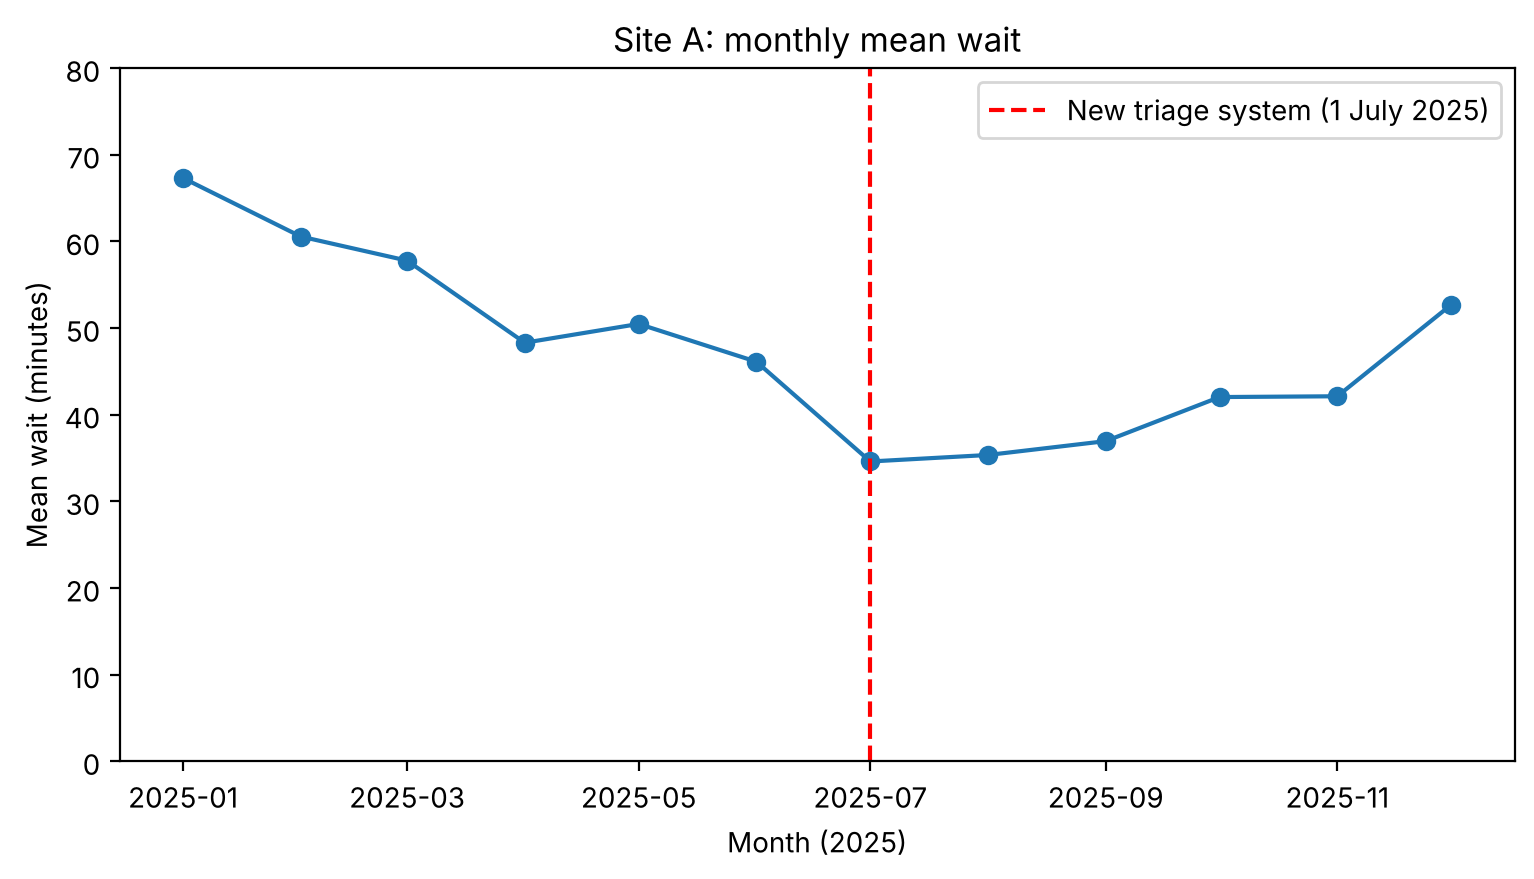

In [12]:
monthlyA = siteA.groupby('month').wait_minutes.mean()

plt.figure(figsize=(9, 4.5))
plt.plot(monthlyA.index, monthlyA.values, marker='o', color='tab:blue')
plt.axvline(pd.Timestamp('2025-07-01'), color='red', linestyle='--', label='New triage system (1 July 2025)')
plt.ylim(0, 80)
plt.xlabel('Month (2025)')
plt.ylabel('Mean wait (minutes)')
plt.title('Site A: monthly mean wait')
plt.legend()
plt.show()

Part 2: the same chart for Site A and Site B together, and the monthly numbers. Site B never got the new system, so it shows what happens without it.

site        Site A  Site B
month                     
2025-01-01    67.3    66.1
2025-02-01    60.6    63.9
2025-03-01    57.8    53.9
2025-04-01    48.3    54.1
2025-05-01    50.5    47.6
2025-06-01    46.1    39.8
2025-07-01    34.6    37.9
2025-08-01    35.4    38.2
2025-09-01    37.0    43.0
2025-10-01    42.0    47.0
2025-11-01    42.1    49.2
2025-12-01    52.7    60.5


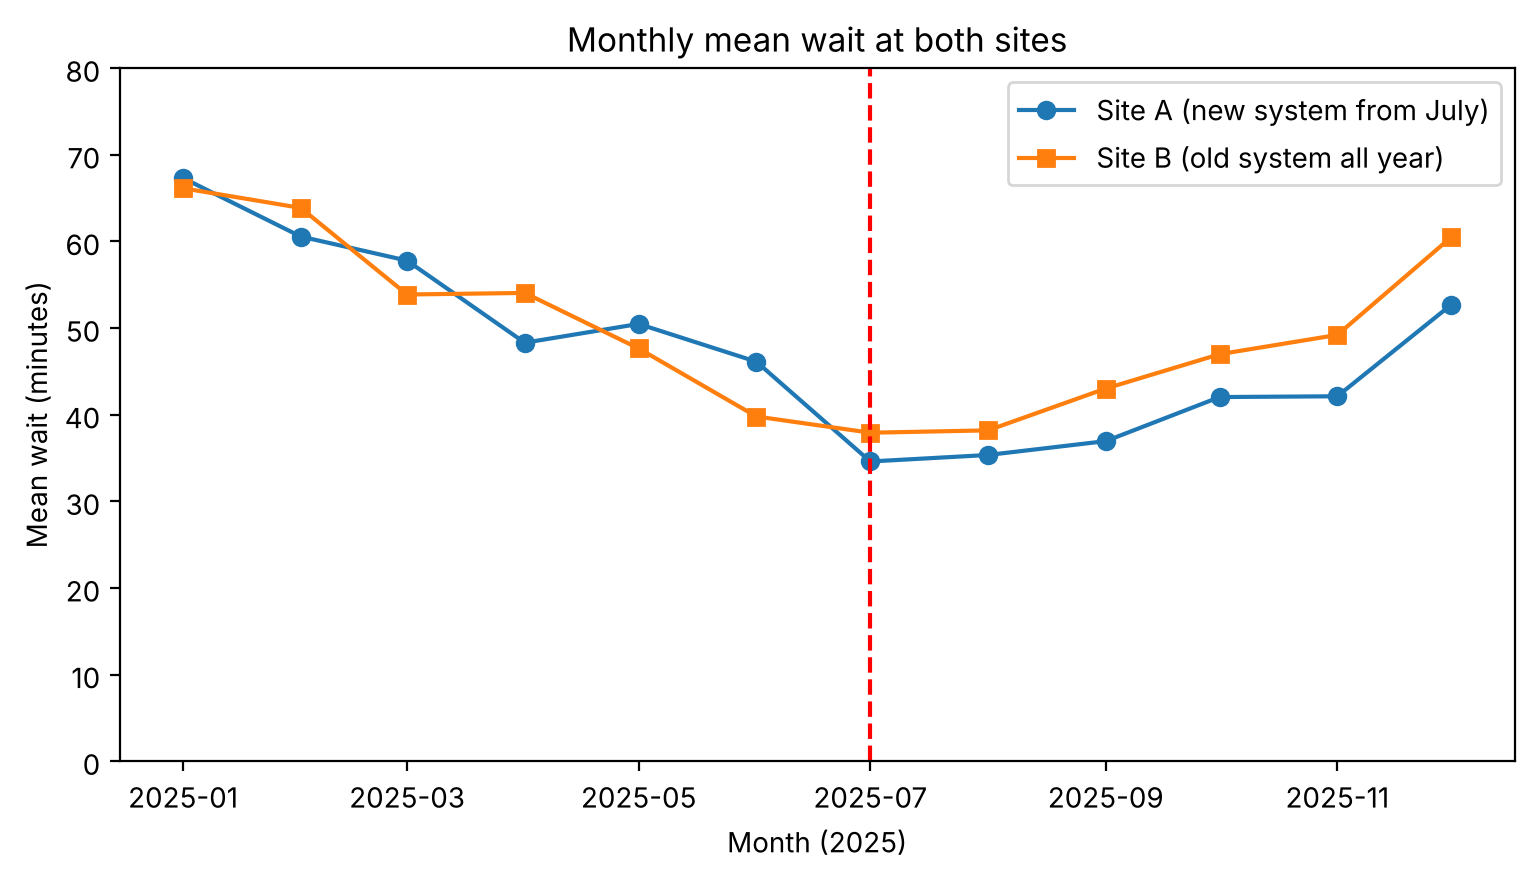

In [13]:
monthly = clean.pivot_table(index='month', columns='site', values='wait_minutes', aggfunc='mean')
print(monthly.round(1))

plt.figure(figsize=(9, 4.5))
plt.plot(monthly.index, monthly['Site A'], marker='o', color='tab:blue', label='Site A (new system from July)')
plt.plot(monthly.index, monthly['Site B'], marker='s', color='tab:orange', label='Site B (old system all year)')
plt.axvline(pd.Timestamp('2025-07-01'), color='red', linestyle='--')
plt.ylim(0, 80)
plt.xlabel('Month (2025)')
plt.ylabel('Mean wait (minutes)')
plt.title('Monthly mean wait at both sites')
plt.legend()
plt.show()

Part 3: Site B before and after the same date, then the difference in differences.

In [14]:
table = clean.groupby(['site', 'post']).wait_minutes.agg(['mean', 'count']).round(2)
print(table)

change = clean.groupby(['site', 'post']).wait_minutes.mean().unstack()
change['change'] = change[True] - change[False]
print()
print(change.round(2))

a = change.loc['Site A', 'change']
b = change.loc['Site B', 'change']
print()
print('Site A change:', round(a, 2))
print('Site B change:', round(b, 2))
print('Site A change minus Site B change:', round(a - b, 2))

               mean  count
site   post               
Site A False  54.98   1169
       True   40.86   1175
Site B False  54.09    920
       True   46.28    905

post    False   True  change
site                        
Site A  54.98  40.86  -14.12
Site B  54.09  46.28   -7.82

Site A change: -14.12
Site B change: -7.82
Site A change minus Site B change: -6.3


### Answers

Q1. The AI says waits improved after the new system. Does the data show that the system caused it?

No. At Site A the mean wait went from 55.0 minutes before July to 40.9 minutes after, a drop of 14.1 minutes, with about 1,170 visits in each period. That shows the wait was lower after July, but a before and after comparison cannot say why. Anything else that changed around July is mixed into the same number, such as the time of year, the type of patients, or the department mix.

Q2. What happens to waits in the second half of the year even without any new system?

Waits at both sites follow a clear seasonal pattern. They fall from about 66 minutes in January to a low in July and August (about 35 to 38 minutes), and then rise again to about 53 minutes at Site A and 60 minutes at Site B by December. Site B never got the new system, yet its waits also fell sharply going into July. So part of the drop at Site A would have happened anyway. Also, the waits start rising again from September at both sites, so the benefit of the new system cannot simply be read off the second half of the year.

Q3. Which site could you use as a comparison? What is its change over the same dates?

Site B. It is in the same hospital, covers the same months, and kept the old triage system. Its mean wait went from 54.1 minutes before July to 46.3 minutes after, a drop of 7.8 minutes.

Q4. Site A's change minus Site B's change. What does the answer mean?

Site A dropped by 14.1 minutes and Site B dropped by 7.8 minutes, so the difference is about minus 6.3 minutes. This is the difference in differences estimate. It means Site A's waits fell about 6.3 minutes more than Site B's over the same dates. Roughly 7.8 of Site A's 14.1 minute drop would likely have happened without the new system, because Site B shows the same drop with the old one. So the new system is associated with about 6.3 minutes of improvement, less than half of the headline 14.1 minutes. This is still not proof of causation. It assumes both sites would have followed the same trend without the new system, and it does not yet account for the department mix or triage level (Task 8) or give a confidence interval.

Q5. Improved prompt

The original prompt only compares Site A with itself. The improved prompt below adds a comparison site, the seasonal context, the valid row definition, and wording that avoids causation.

> Context: the attached CSV has hospital visits with columns visit_id, visit_date, site, department, triage_level, age, wait_minutes, treatment_minutes, satisfaction, triage_system. Site A switched to a new triage system on 1 July 2025. Site B kept the old system all year. The data has known problems: two date formats (YYYY-MM-DD and DD/MM/YYYY), department labels written as Emergency, emergency, ER and with trailing spaces, exact duplicate rows, negative waits, waits of 999 as a placeholder, and impossible ages.
>
> Task: first clean the data in pandas and tell me how many rows each step removes. Use valid rows only: parse both date formats, map the Emergency labels to one value, drop exact duplicates, drop wait_minutes that are zero, negative or 999, and drop ages below 0 or above 110. Then (1) compare mean wait_minutes at Site A before and after 1 July 2025 with n for each period, (2) do the same for Site B over the same dates, (3) compute Site A's change minus Site B's change, (4) show a monthly line chart of mean wait for both sites in the same figure with a vertical line at 1 July, axes labelled in minutes, and the y axis starting at 0.
>
> Constraints: do not say the new system caused the change. Use association language. Point out any seasonal pattern you see in the monthly numbers and say what the difference in differences does and does not control for. Show the pandas code.

### AI result

#### Original prompt output

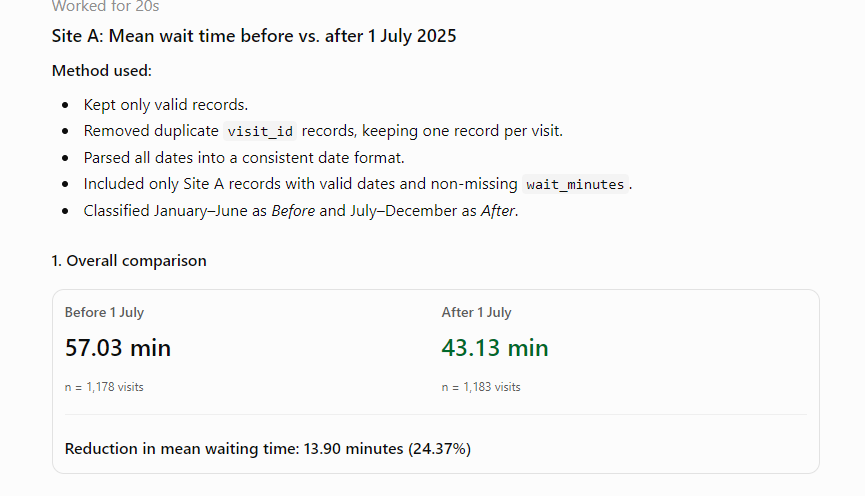

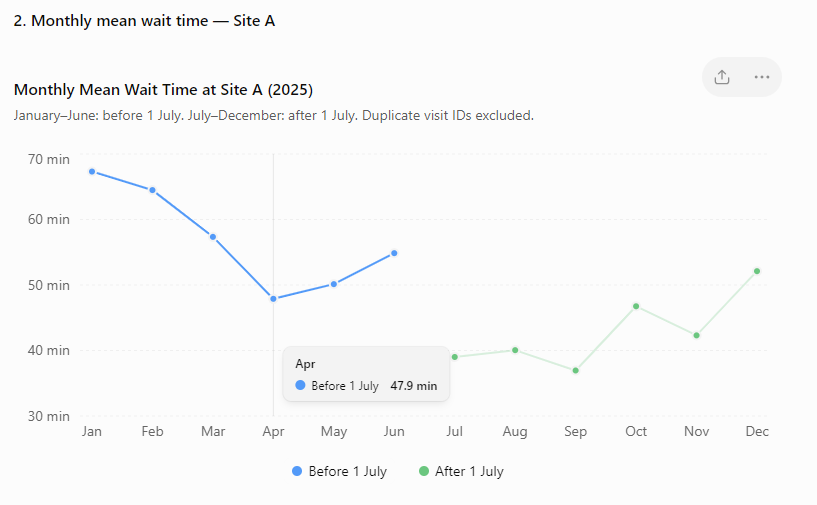

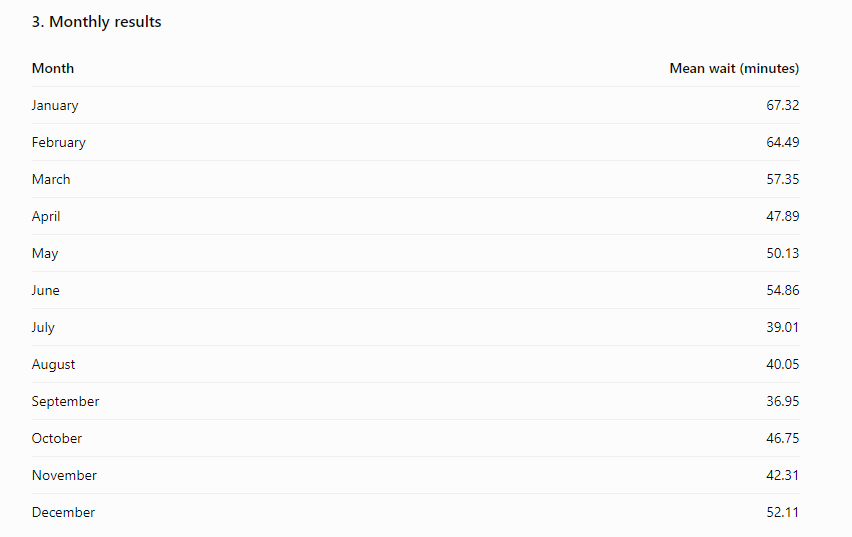

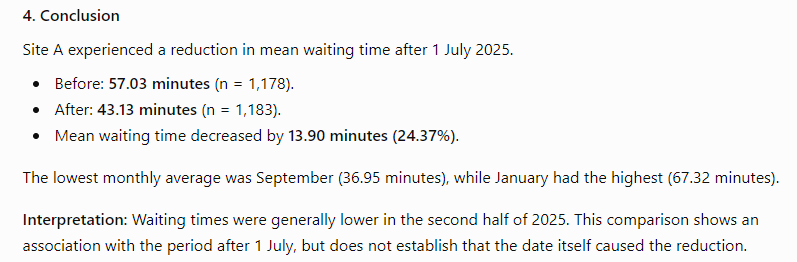

#### Improved prompt output

```
Hospital Triage System Analysis – Before and After Implementation
This analysis uses the attached hospital_wait_times.csv file.

We will first clean the data according to your specified rules, then compare waiting times at Site A and Site B before and after 1 July 2025.

Important: Site B acts as the comparison group because it continued using the old triage system. The analysis will examine associations, not claim that the new system caused any change.

Original dataset: 4,225 rows and 10 columns.

The original data will remain unchanged. Cleaning will be performed on a separate DataFrame.
1. Data cleaning
The cleaning steps will be performed in this order:
1. Parse both date formats.
2. Standardize Emergency department labels.
3. Remove exact duplicate rows.
4. Remove zero, negative, and 999 waiting times.
5. Remove impossible ages (below 0 or above 110).
Each step will report how many rows it removes.
Cleaning results
Rows removed at each step, in the specified order
Cleaning step	Rows removed	Rows remaining
Original dataset	—	4,225
Parse both date formats	0	4,225
Standardize department labels	0	4,225
Remove exact duplicates	25	4,200
Remove invalid waiting times	25	4,175
Remove impossible ages	6	4,169

Department standardization changes 72 values but does not remove rows:
- Emergency → Emergency
- emergency → Emergency
- ER → Emergency
- Emergency  → Emergency
All 4,225 dates parsed successfully: 3,869 ISO dates and 356 day/month/year dates.
4,169 valid rows remaining
2. Site A: Before and after implementation
The transition date is 1 July 2025.
Period	Number of visits (n)	Mean waiting time
Before 1 July	1,169	54.98 minutes
From 1 July onwards	1,175	40.87 minutes

Change in mean waiting time:
\[
40.865-54.982=-14.117
\]

Site A's mean waiting time decreased by approximately 14.12 minutes.
3. Site B: Before and after the same date
Site B continued using the old triage system throughout the year.
Period	Number of visits (n)	Mean waiting time
Before 1 July	920	54.09 minutes
From 1 July onwards	905	46.28 minutes

Change in mean waiting time:
\[
46.276-54.093=-7.817
\]

Site B's mean waiting time decreased by approximately 7.82 minutes.
4. Difference-in-differences calculation
The difference-in-differences (DiD) calculation compares the change at Site A with the change at Site B.

Formula:
\[
DiD=(A_{after}-A_{before})-(B_{after}-B_{before})
\]

Substituting the values:
\[
=(-14.117)-(-7.817)
\]

\[
\boxed{DiD=-6.30\text{ minutes}}
\]

Difference-in-differences estimate
−6.30 minutes
Site A's waiting-time reduction was approximately 6.30 minutes greater than Site B's reduction.

This is an association-based comparison, not proof that the new triage system caused the additional reduction.
5. Monthly waiting-time trend
The chart below shows the monthly mean waiting time for both sites in the same figure.

The dashed vertical line marks 1 July 2025.


 
The generated chart is available here:

Download monthly waiting-time chart
Monthly mean waiting times
Month	Site A (minutes)	Site B (minutes)
January	67.32	66.14
February	60.57	63.88
March	57.79	53.88
April	48.31	54.06
May	50.48	47.65
June	46.12	39.79
July	34.60	37.92
August	35.35	38.19
September	36.95	43.02
October	42.04	46.99
November	42.13	49.21
December	52.70	60.50

Seasonal pattern observed
There is a noticeable pattern shared by both sites:
1. January to June: Mean waiting times generally decrease.
2. July and August: Both sites experience relatively low waiting times.
3. September to November: Waiting times gradually increase.
4. December: Both sites experience a noticeable increase.
Site B also experiences this pattern despite not changing its triage system.

This suggests that factors affecting both sites, such as seasonal patient demand, staffing levels, or hospital operations, may be associated with changes in waiting times.

However, because the dataset covers only one year, we cannot establish that this is a recurring seasonal pattern.
6. What difference-in-differences controls for
Difference-in-differences compares the change at Site A against the change at Site B.

What it helps control for:
- Changes over time that affect both sites similarly.
- Shared seasonal patterns.
- General hospital-wide changes affecting both locations.
- The initial difference in average waiting times between the two sites.
For example, Site B's waiting time also decreased by 7.82 minutes. DiD accounts for this shared reduction when comparing Site A's change.

What it does NOT automatically control for:
- Changes that affect Site A but not Site B.
- Different staffing changes at either site.
- Changes in patient severity or patient volume.
- Changes in department workload.
- Different trends between the sites before implementation.
- Other changes introduced at Site A around July.
An important assumption is parallel trends: without the new system, Site A and Site B would have continued following similar trends.

The data shows that their monthly trends are not identical, so this assumption cannot simply be taken for granted.

Also, one year of data and one implementation date are insufficient to establish the parallel-trends assumption confidently.

Interpretation: The estimated additional reduction of 6.30 minutes is consistent with a more favourable change at Site A relative to Site B, but it cannot be interpreted as the causal effect of the new triage system.
7. Complete Python code
The following is the complete code to reproduce the cleaning, row counts, before-and-after comparisons, DiD calculation, monthly summary, and chart.

You can run it in Jupyter Notebook or Google Colab.
dates.loc[slash] = pd.to_datetime(print("\nMONTHLY MEAN WAITING TIMES")print(monthly.round(2))# STEP 11: Plot both sites on the same chartplt.figure(figsize=(11, 6))plt.plot(    monthly.index,    monthly["Site A"],    marker="o",    label="Site A")plt.plot(    monthly.index,    monthly["Site B"],    marker="o",    label="Site B")# Mark implementation dateplt.axvline(    pd.Timestamp("2025-07-01"),    color="black",    linestyle="--",    label="New system introduced (1 July)")plt.title("Monthly Mean Waiting Time by Site (2025)")plt.xlabel("Month")plt.ylabel("Mean waiting time (minutes)")plt.ylim(bottom=0)plt.legend()plt.grid(True, alpha=0.3)plt.xticks(rotation=45)plt.tight_layout()plt.show()




8. Final results summary
Measure	Site A	Site B
Before mean	54.98	54.09
After mean	40.87	46.28
Change	-14.12	-7.82
Before sample size	1,169	920
After sample size	1,175	905

Final DiD result
−6.30 minutes
Additional reduction in mean waiting time at Site A relative to Site B.

Overall conclusion: Both hospitals experienced lower mean waiting times after July. Site A experienced a larger reduction than Site B. The difference-in-differences estimate was −6.30 minutes, indicating a more favourable relative change at Site A. However, shared seasonal patterns, possible site-specific changes, and the parallel-trends assumption must be considered before interpreting this as an effect of the new triage system.
```

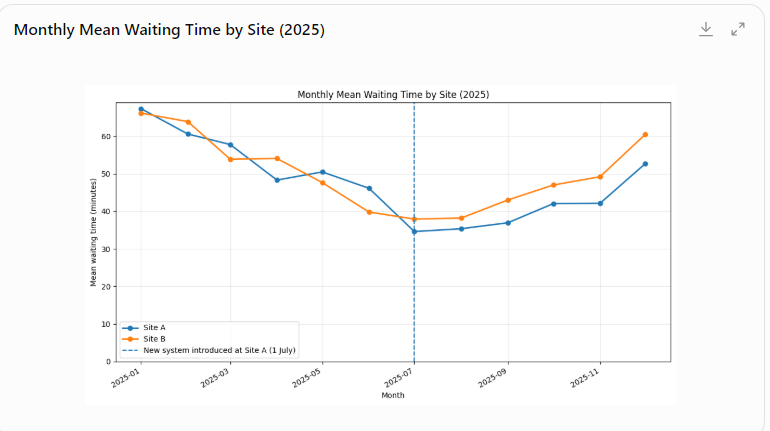

#### Python code given with the improved prompt output

```
import pandas as pd
import matplotlib.pyplot as plt

# Load original dataset
df = pd.read_csv("hospital_wait_times.csv")

print("Original rows:", len(df))

# Create a separate copy
clean = df.copy()


# STEP 1: Parse both date formats

iso = clean["visit_date"].str.match(
    r"^\d{4}-\d{2}-\d{2}$"
)

slash = clean["visit_date"].str.match(
    r"^\d{2}/\d{2}/\d{4}$"
)

dates = pd.Series(
    pd.NaT,
    index=clean.index,
    dtype="datetime64[ns]"
)

dates.loc[iso] = pd.to_datetime(
    clean.loc[iso, "visit_date"],
    format="%Y-%m-%d",
    errors="coerce"
)

dates.loc[slash] = pd.to_datetime(
    clean.loc[slash, "visit_date"],
    format="%d/%m/%Y",
    errors="coerce"
)

clean["parsed_date"] = dates

before = len(clean)

clean = clean[clean["parsed_date"].notna()].copy()

print("Rows removed due to invalid dates:",
      before - len(clean))


# STEP 2: Standardize department labels

original_department = clean["department"].copy()

department = clean["department"].str.strip()

department_lower = department.str.lower()

clean["department"] = department_lower.map({
    "emergency": "Emergency",
    "er": "Emergency"
}).fillna(department)

print("Department values standardized:",
      (original_department != clean["department"]).sum())

print("Unique departments:")
print(clean["department"].unique())


# STEP 3: Remove exact duplicate rows

before = len(clean)

clean = clean.drop_duplicates()

print("Duplicate rows removed:",
      before - len(clean))


# STEP 4: Remove invalid waiting times

before = len(clean)

invalid_wait = (
    (clean["wait_minutes"] <= 0) |
    (clean["wait_minutes"] == 999)
)

clean = clean[~invalid_wait].copy()

print("Invalid waiting-time rows removed:",
      before - len(clean))


# STEP 5: Remove impossible ages

before = len(clean)

invalid_age = (
    (clean["age"] < 0) |
    (clean["age"] > 110)
)

clean = clean[~invalid_age].copy()

print("Impossible age rows removed:",
      before - len(clean))


# Final cleaned dataset

print("\nFinal number of rows:", len(clean))


# STEP 6: Divide data into before and after periods

before_period = clean[
    clean["parsed_date"] < "2025-07-01"
]

after_period = clean[
    clean["parsed_date"] >= "2025-07-01"
]


# STEP 7: Compare Site A

site_a_before = before_period[
    before_period["site"] == "Site A"
]

site_a_after = after_period[
    after_period["site"] == "Site A"
]

a_before_mean = site_a_before["wait_minutes"].mean()
a_after_mean = site_a_after["wait_minutes"].mean()

a_change = a_after_mean - a_before_mean

print("\nSITE A")

print("Before n:", len(site_a_before))
print("Before mean:", round(a_before_mean, 2))

print("After n:", len(site_a_after))
print("After mean:", round(a_after_mean, 2))

print("Change:", round(a_change, 2))


# STEP 8: Compare Site B

site_b_before = before_period[
    before_period["site"] == "Site B"
]

site_b_after = after_period[
    after_period["site"] == "Site B"
]

b_before_mean = site_b_before["wait_minutes"].mean()
b_after_mean = site_b_after["wait_minutes"].mean()

b_change = b_after_mean - b_before_mean

print("\nSITE B")

print("Before n:", len(site_b_before))
print("Before mean:", round(b_before_mean, 2))

print("After n:", len(site_b_after))
print("After mean:", round(b_after_mean, 2))

print("Change:", round(b_change, 2))


# STEP 9: Difference-in-differences

did = a_change - b_change

print("\nDIFFERENCE-IN-DIFFERENCES")

print("Site A change:", round(a_change, 2))
print("Site B change:", round(b_change, 2))

print("DiD:", round(did, 2), "minutes")


# STEP 10: Calculate monthly mean waiting times

clean["month"] = (
    clean["parsed_date"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly = clean.groupby(
    ["month", "site"]
)["wait_minutes"].mean().unstack()

print("\nMONTHLY MEAN WAITING TIMES")

print(monthly.round(2))


# STEP 11: Plot both sites on the same chart

plt.figure(figsize=(11, 6))

plt.plot(
    monthly.index,
    monthly["Site A"],
    marker="o",
    label="Site A"
)

plt.plot(
    monthly.index,
    monthly["Site B"],
    marker="o",
    label="Site B"
)

# Mark implementation date

plt.axvline(
    pd.Timestamp("2025-07-01"),
    color="black",
    linestyle="--",
    label="New system introduced (1 July)"
)

plt.title("Monthly Mean Waiting Time by Site (2025)")

plt.xlabel("Month")
plt.ylabel("Mean waiting time (minutes)")

plt.ylim(bottom=0)

plt.legend()
plt.grid(True, alpha=0.3)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()
```

## Task 3: Which departments improved?

Part 1: standardise the department labels and count how many rows changed. We count on the raw file, before any rows are dropped.

In [15]:
raw = pd.read_csv('dataset/hospital_wait_times.csv')
fixed = raw.department.str.strip().str.lower().replace({'er': 'emergency'}).str.title()

print('Rows whose label changed:', (raw.department != fixed).sum())
print()
print(pd.DataFrame({'before': raw.department.value_counts(), 'after': fixed.value_counts()}).fillna(0).astype(int))

Rows whose label changed: 72

             before  after
department                
Cardiology      637    637
ER               26      0
Emergency      1204   1276
Emergency        27      0
Orthopedics     651    651
Pediatrics      767    767
Radiology       894    894
emergency        19      0


Part 2: mean wait by department before and after 1 July, both sites combined, as a grouped bar chart. The valid rows in clean are used.

             Before 1 July  From 1 July  n before  n after  change
department                                                        
Cardiology           51.66        45.57       320      310   -6.09
Emergency            73.46        63.16       676      582  -10.29
Orthopedics          61.82        51.17       365      277  -10.65
Pediatrics           41.80        35.63       389      363   -6.17
Radiology            26.64        21.72       339      548   -4.92


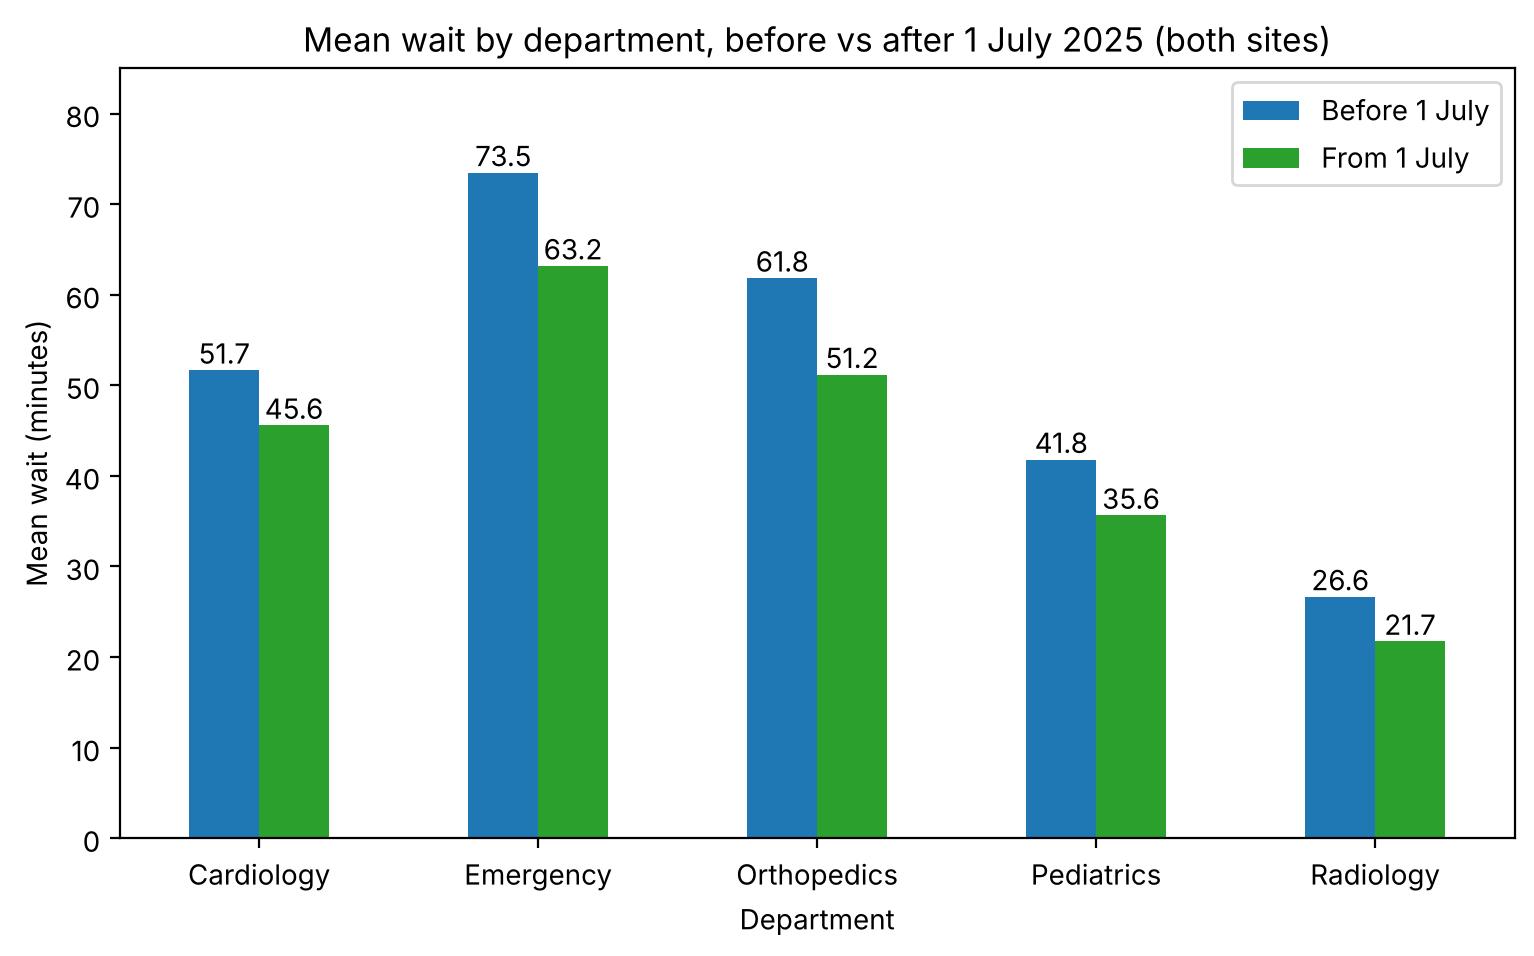

In [16]:
means = clean.groupby(['department', 'post']).wait_minutes.mean().unstack()
means.columns = ['Before 1 July', 'From 1 July']
counts = clean.groupby(['department', 'post']).wait_minutes.count().unstack()
counts.columns = ['n before', 'n after']

table = pd.concat([means, counts], axis=1)
table['change'] = table['From 1 July'] - table['Before 1 July']
print(table.round(2))

ax = means.plot(kind='bar', figsize=(9, 5), color=['tab:blue', 'tab:green'])
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.1f')
ax.set_ylim(0, 85)
ax.set_xlabel('Department')
ax.set_ylabel('Mean wait (minutes)')
ax.set_title('Mean wait by department, before vs after 1 July 2025 (both sites)')
plt.xticks(rotation=0)
plt.show()

Part 3: each department's share of all visits before and after July.

In [17]:
share = clean.groupby('post').department.value_counts(normalize=True).unstack(0) * 100
share.columns = ['Before 1 July (%)', 'From 1 July (%)']
share['change (points)'] = share['From 1 July (%)'] - share['Before 1 July (%)']
print(share.round(1))

overall = clean.groupby('post').wait_minutes.mean()
print()
print('Overall mean before:', round(overall[False], 2))
print('Overall mean after:', round(overall[True], 2))
print('Overall change:', round(overall[True] - overall[False], 2))

             Before 1 July (%)  From 1 July (%)  change (points)
department                                                      
Cardiology                15.3             14.9             -0.4
Emergency                 32.4             28.0             -4.4
Orthopedics               17.5             13.3             -4.2
Pediatrics                18.6             17.5             -1.2
Radiology                 16.2             26.3             10.1

Overall mean before: 54.59
Overall mean after: 43.22
Overall change: -11.37


Part 4: the overall change if the department mix had not changed. We keep the before-July mix of visits fixed and apply it to the department means from both periods. Then we repeat it with the after-July mix as a check.

In [18]:
mix_before = clean[~clean.post].department.value_counts(normalize=True)
mix_after = clean[clean.post].department.value_counts(normalize=True)

dept_before = clean[~clean.post].groupby('department').wait_minutes.mean()
dept_after = clean[clean.post].groupby('department').wait_minutes.mean()

fixed_mix_before = (dept_after * mix_before).sum() - (dept_before * mix_before).sum()
fixed_mix_after = (dept_after * mix_after).sum() - (dept_before * mix_after).sum()
overall_change = overall[True] - overall[False]

print('Overall change as observed:', round(overall_change, 2))
print('Change with before-July mix held fixed:', round(fixed_mix_before, 2))
print('Change with after-July mix held fixed:', round(fixed_mix_after, 2))
print()
print('Part due to the mix shift (before-July mix):', round(overall_change - fixed_mix_before, 2), 'minutes')
print('Share of the overall drop:', round((overall_change - fixed_mix_before) / overall_change * 100, 1), '%')

Overall change as observed: -11.37
Change with before-July mix held fixed: -8.07
Change with after-July mix held fixed: -7.58

Part due to the mix shift (before-July mix): -3.3 minutes
Share of the overall drop: 29.0 %


### Answers

Q1. The overall drop is 11.4 minutes, yet the department drops are 4.9 to 10.6. Is that suspicious?

Yes. If the department mix stayed the same, the overall change would be a weighted average of the department changes, so it could never be bigger than the biggest department change. Here the overall drop (11.4) is larger than every single department's drop (the largest is Orthopedics at 10.6). The only way that can happen is that the mix of patients changed between the two periods. This is a form of Simpson's paradox: the overall number tells a different story from the department numbers.

Q2. Each department's share of visits before and after July. Which one changed most?

Radiology changed the most. Its share of all visits went from 16.2 percent to 26.3 percent, an increase of 10.1 points. Emergency fell from 32.4 to 28.0 percent and Orthopedics from 17.5 to 13.3 percent. Cardiology and Pediatrics barely moved.

Q3. Radiology has the shortest waits. What does a growing Radiology share do to the hospital-wide average?

It pulls the average down. Radiology waits are about 27 minutes before and 22 after, far below Emergency at 73 and 63. When a larger share of visits is made up of short-wait Radiology visits, the hospital-wide mean falls even if no single department got faster. So part of the overall drop comes from who is being seen and not from how fast anyone is seen.

Q4. Recompute the overall change as if the mix had not changed. How much of the 11.4 was just mix?

Holding the before-July mix fixed, the overall change is about minus 8.1 minutes instead of minus 11.4. So about 3.3 minutes, roughly 29 percent of the headline drop, comes from the mix shift. Holding the after-July mix fixed gives minus 7.6, which would make the mix part about 3.8 minutes. Either way, roughly a third of the headline drop is mix, and the improvement within departments is about 8 minutes.

Q5. Improved prompt

The original prompt asks only for department means. It never asks for the number of visits or the share of visits in each department, so the AI cannot show or correct the change in mix. The improved prompt adds those and asks for a mix-adjusted overall change.

> Context: the attached CSV has hospital visits with columns visit_id, visit_date, site, department, triage_level, age, wait_minutes, treatment_minutes, satisfaction, triage_system. The data has known problems: two date formats (YYYY-MM-DD and DD/MM/YYYY), department labels written as Emergency, emergency, ER and with trailing spaces, exact duplicate rows, negative waits, waits of 999 as a placeholder, and impossible ages (below 0 or above 110).
>
> Task: first clean the data in pandas, mapping all Emergency labels to Emergency, and tell me how many department labels changed. Use valid rows only: parse both date formats, drop exact duplicates, drop wait_minutes that are zero, negative or 999, and drop impossible ages. Then, for both sites combined, (1) show the mean wait_minutes and the number of visits n by department before and after 1 July 2025, (2) show each department's share of all visits before and after 1 July, (3) compute the overall change in mean wait, (4) recompute the overall change with the before-July department mix held fixed, and say how much of the overall change is due to the change in mix, (5) show a grouped bar chart of mean wait by department before vs after, with the y axis starting at 0, axes labelled in minutes, and values on the bars.
>
> Constraints: check whether the overall change is larger than every department change, and if so explain why in terms of department mix. Use association language, not causal language. Show the pandas code.

### AI result

#### Original prompt output

```
Valid rows used: 4169

Mean wait_minutes by department (both sites):
             Before 1 July  From 1 July
department                             
Cardiology           51.66        45.57
Emergency            73.46        63.16
Orthopedics          61.82        51.17
Pediatrics           41.80        35.63
Radiology            26.64        21.72
```

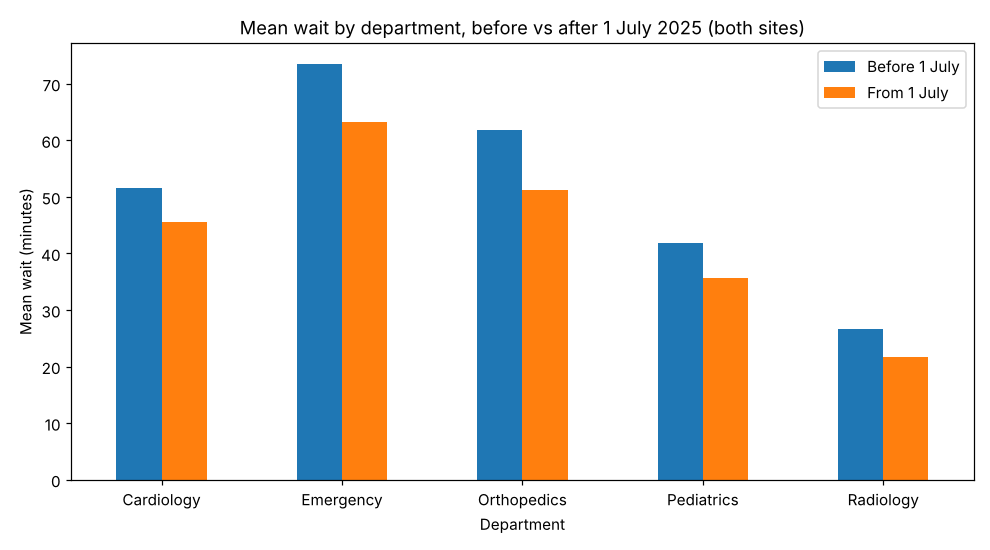

#### Improved prompt output

```
Original rows: 4225
Department labels changed: 72
Dates that failed to parse: 0
Exact duplicates removed: 25
Invalid waits removed: 25
Impossible ages removed: 6
Valid rows: 4169

(1) Mean wait and n by department (both sites):
             mean before  mean after  change  n before  n after
department                                                     
Cardiology         51.66       45.57   -6.09       320      310
Emergency          73.46       63.16  -10.29       676      582
Orthopedics        61.82       51.17  -10.65       365      277
Pediatrics         41.80       35.63   -6.17       389      363
Radiology          26.64       21.72   -4.92       339      548

(2) Share of all visits (%):
period       Before 1 July  From 1 July  change (points)
department                                              
Cardiology            15.3         14.9             -0.4
Emergency             32.4         28.0             -4.4
Orthopedics           17.5         13.3             -4.2
Pediatrics            18.6         17.5             -1.2
Radiology             16.2         26.3             10.1

(3) Overall mean wait: before 54.59, after 43.22, change -11.37
Largest department drop: -10.65 (Orthopedics)
Overall change larger than every department change: True

(4) Overall change with before-July mix held fixed: -8.07
Change due to mix shift: -3.30 minutes (29.0% of the overall change)
```

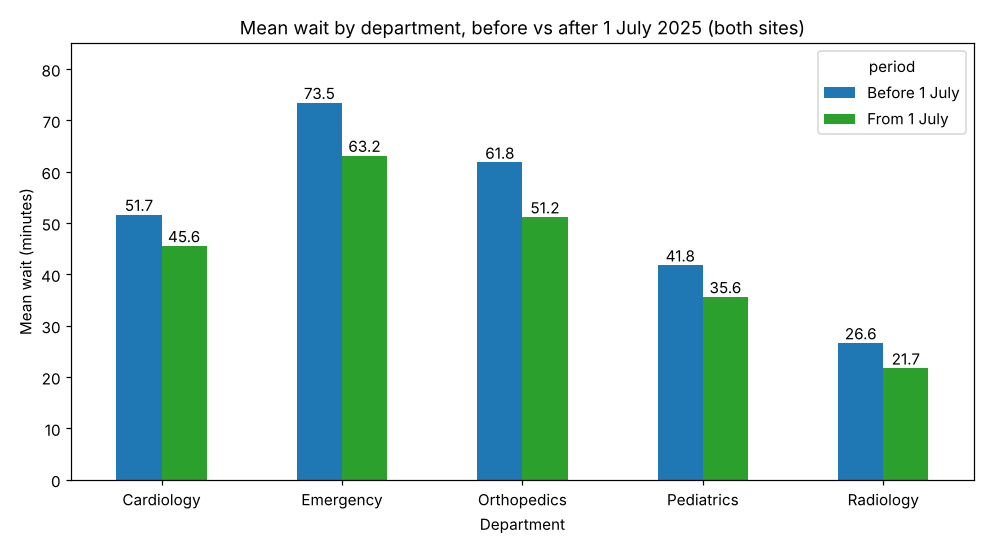

## Task 4: Does waiting reduce satisfaction?

Part 1: what the given prompt asks for. Missing scores are not filled in, so every calculation uses only rows that have a satisfaction score.

In [19]:
sat = clean.dropna(subset=['satisfaction']).copy()
sat['group'] = (sat.wait_minutes > 90).map({False: '90 or less', True: 'over 90'})

print(sat.groupby('group').satisfaction.agg(['mean', 'count']).round(2))
print()
print('Overall mean satisfaction:', round(sat.satisfaction.mean(), 2))
print('Correlation wait vs satisfaction:', round(sat.wait_minutes.corr(sat.satisfaction), 3))

            mean  count
group                  
90 or less  3.65   3375
over 90     2.28    283

Overall mean satisfaction: 3.54
Correlation wait vs satisfaction: -0.557


Part 2: how many scores are missing in each wait group.

In [20]:
clean['group'] = (clean.wait_minutes > 90).map({False: '90 or less', True: 'over 90'})
missing = clean.groupby('group').satisfaction.agg(visits='size', missing=lambda s: s.isna().sum())
missing['missing %'] = (missing.missing / missing.visits * 100).round(1)
print(missing)

            visits  missing  missing %
group                                 
90 or less    3664      289        7.9
over 90        505      222       44.0


Part 3: which patients have no score. We compare the missing rate by wait band, triage level and department.

In [21]:
clean['wait_band'] = pd.cut(clean.wait_minutes, [0, 30, 60, 90, 120, 180, 1000])
print('Missing % by wait band')
print((clean.groupby('wait_band', observed=True).satisfaction.apply(lambda s: s.isna().mean() * 100)).round(1))
print()
print('Missing % by triage level')
print((clean.groupby('triage_level').satisfaction.apply(lambda s: s.isna().mean() * 100)).round(1))
print()
print('Missing % by department')
print((clean.groupby('department').satisfaction.apply(lambda s: s.isna().mean() * 100)).round(1))

Missing % by wait band
wait_band
(0, 30]         7.9
(30, 60]        7.8
(60, 90]        7.9
(90, 120]      45.7
(120, 180]     39.6
(180, 1000]    52.6
Name: satisfaction, dtype: float64

Missing % by triage level
triage_level
1    12.4
2     6.9
3    10.8
4    14.5
5    18.3
Name: satisfaction, dtype: float64

Missing % by department
department
Cardiology     10.6
Emergency      16.9
Orthopedics    12.8
Pediatrics      9.7
Radiology       8.6
Name: satisfaction, dtype: float64


Part 4: how much could the overall mean move? If every missing score had been a 1, or a 5, the overall mean would be:

In [22]:
n_obs = clean.satisfaction.notna().sum()
n_miss = clean.satisfaction.isna().sum()
total = clean.satisfaction.sum()
print('If all missing were 1:', round((total + 1 * n_miss) / (n_obs + n_miss), 2))
print('If all missing were 5:', round((total + 5 * n_miss) / (n_obs + n_miss), 2))
print('Observed mean:', round(clean.satisfaction.mean(), 2))

If all missing were 1: 3.23
If all missing were 5: 3.72
Observed mean: 3.54


### Answers

Q1. The prompt said not to fill missing values. Is there still a problem left?

Yes. Not filling the gaps stops us inventing numbers, but it does not make the averages fair. The scores that are missing are not missing at random, so every average only describes the patients who chose to answer. The prompt also never asks how many scores are missing in each group, so the output looks complete when it is not.

Q2. Percentage of missing satisfaction scores in each wait group.

Among visits with a wait of 90 minutes or less, 289 of 3,664 have no score, which is 7.9 percent. Among visits that waited more than 90 minutes, 222 of 505 have no score, which is 44.0 percent. Long waiters are more than five times as likely to have no score.

Q3. Which kind of patient is most likely to have no score?

Patients who waited a long time. The missing rate is about 8 percent in every wait band up to 90 minutes and then jumps to between 40 and 53 percent for waits above 90 minutes. Triage level 5 (18 percent) and Emergency (17 percent) also have higher missing rates, but these differences are much smaller than the jump after 90 minutes.

Q4. Is 3.54 likely too high or too low for all patients? Why can't you be sure?

It is probably too high. The patients who are missing are mostly the long waiters, and the long waiters who did answer gave an average of only 2.3. If the missing long waiters were similarly unhappy, the true average for all patients would be lower than 3.54. We cannot be sure because we do not know what the missing patients would have said. They might have left without answering for other reasons. The most we can say is that if every missing score were a 1 the overall mean would be 3.23, and if every one were a 5 it would be 3.72, so the true value lies somewhere in that range and the observed mean is only a rough guide.

Q5. Improved prompt

The original prompt reports the means and the correlation but never asks how many scores are missing, who is missing, or how much that could change the result. The improved prompt adds those.

> Context: the attached CSV has hospital visits with columns visit_id, visit_date, site, department, triage_level (1 = most urgent, 5 = least urgent), age, wait_minutes, treatment_minutes, satisfaction, triage_system. Site A switched to a new triage system on 1 July 2025 and Site B kept the old one. The data has known problems: two date formats (YYYY-MM-DD and DD/MM/YYYY), department labels written as Emergency, emergency, ER and with trailing spaces, exact duplicate rows, negative waits, waits of 999 as a placeholder, and impossible ages (below 0 or above 110). Task: Use valid rows only: parse both date formats, map the Emergency labels to Emergency, drop exact duplicates, drop wait_minutes that are zero, negative or 999, and drop ages below 0 or above 110. Do not fill in missing values. (1) Report mean satisfaction with n for visits with wait_minutes of 90 or less and for visits over 90, counting only rows that have a score, and the correlation between wait_minutes and satisfaction. (2) Report how many visits and what percentage have no satisfaction score in each wait group. (3) Show whether missing scores are linked to triage level or department. (4) Show the highest and lowest the overall mean satisfaction could be if every missing score were 5 or 1. Constraints: say clearly who the averages describe, use association language, and do not say that waiting causes lower satisfaction. Show the pandas code.

### AI result

#### Original prompt output

```
Valid rows used: 4169

Wait <= 90 minutes: mean satisfaction 3.65 (n = 3375)
Wait > 90 minutes:  mean satisfaction 2.28 (n = 283)
Correlation between wait_minutes and satisfaction: -0.557 (n = 3658)

Missing values were not filled; rows without a satisfaction score are excluded from each calculation.
```

#### Improved prompt output

```
Valid rows used: 4169

(1) Mean satisfaction by wait group (rows with a score only)
           mean  count
group                 
<= 90 min  3.65   3375
> 90 min   2.28    283
Overall mean satisfaction (rows with a score): 3.54
Correlation wait_minutes vs satisfaction: -0.557

(2) Missing satisfaction by wait group
           visits  missing  missing %
group                                
<= 90 min  3664.0    289.0        7.9
> 90 min    505.0    222.0       44.0

(3) Missing satisfaction (%) by triage level and by department
triage_level
1    12.4
2     6.9
3    10.8
4    14.5
5    18.3
department
Cardiology     10.6
Emergency      16.9
Orthopedics    12.8
Pediatrics      9.7
Radiology       8.6

(4) Sensitivity: overall mean satisfaction if every missing score were 1 or 5
Lowest possible overall mean: 3.23, highest possible: 3.72

Note: scores are missing far more often after long waits, so the observed means describe only patients who answered.
These results are associations and do not show that waiting causes lower satisfaction.
```

## Task 5: The board headline

Part 1: the mean, median and 90th percentile of wait_minutes for all valid rows.

In [23]:
w = clean.wait_minutes
print('Mean:', round(w.mean(), 1))
print('Median:', w.median())
print('90th percentile:', w.quantile(0.9))
print('Maximum:', w.max())
print('Skewness:', round(w.skew(), 2))

Mean: 48.9
Median: 39.0
90th percentile: 98.0
Maximum: 351.0
Skewness: 1.93


Part 2: what a chart of means hides. We look at the spread by site and period.

In [24]:
spread = clean.groupby(['site', 'post']).wait_minutes.agg(mean='mean', median='median', p90=lambda s: s.quantile(0.9), n='count')
spread['over 90 min (%)'] = clean.groupby(['site', 'post']).wait_minutes.apply(lambda s: (s > 90).mean() * 100)
print(spread.round(1))

              mean  median    p90     n  over 90 min (%)
site   post                                             
Site A False  55.0    45.0  109.0  1169             15.4
       True   40.9    32.0   82.0  1175              7.9
Site B False  54.1    43.5  111.1   920             16.2
       True   46.3    37.0   88.0   905              9.2


Part 3: the board chart. Left panel is the monthly mean with the monthly 90th percentile as a dotted line, and the right panel shows the shape of the waits.

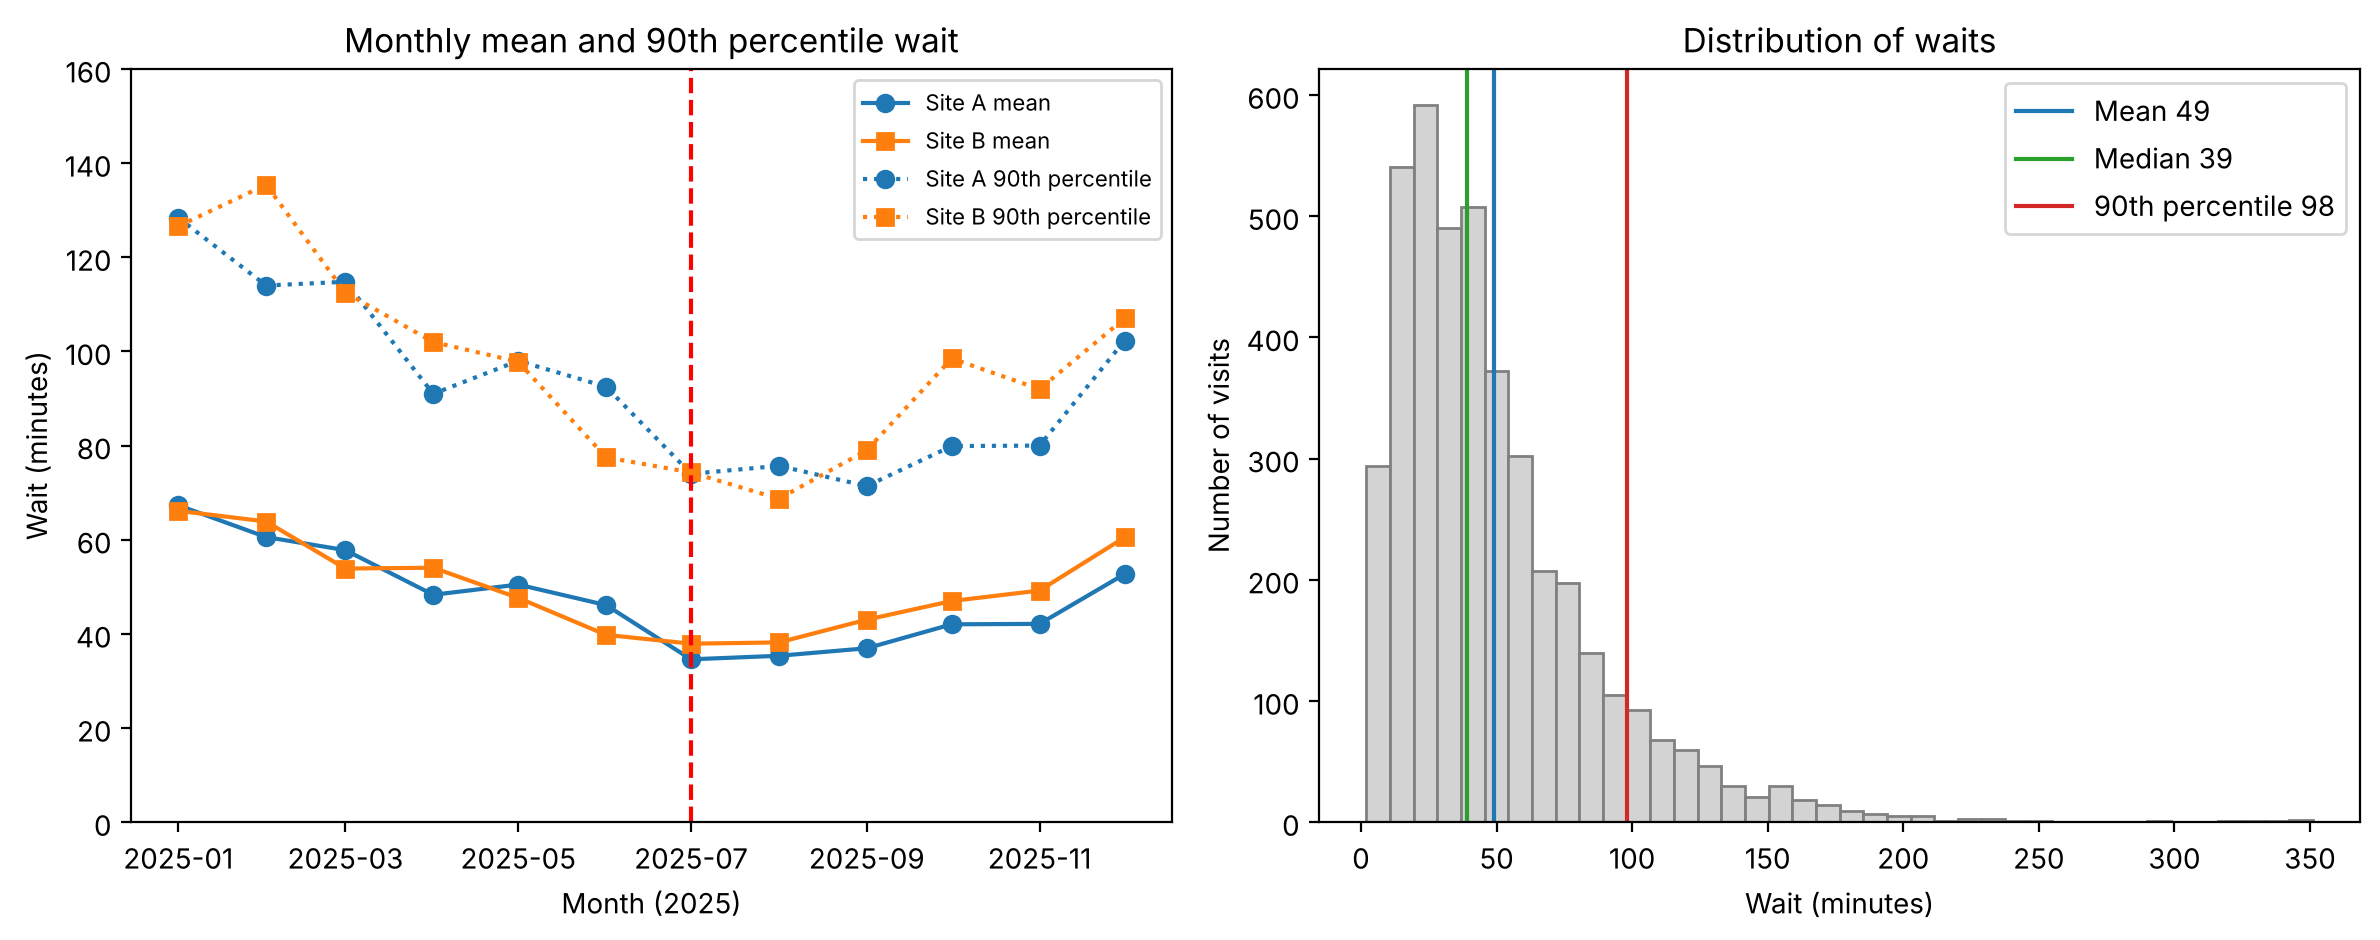

In [25]:
monthly = clean.pivot_table(index='month', columns='site', values='wait_minutes', aggfunc='mean')
monthly90 = clean.pivot_table(index='month', columns='site', values='wait_minutes', aggfunc=lambda s: s.quantile(0.9))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
ax[0].plot(monthly.index, monthly['Site A'], marker='o', color='tab:blue', label='Site A mean')
ax[0].plot(monthly.index, monthly['Site B'], marker='s', color='tab:orange', label='Site B mean')
ax[0].plot(monthly90.index, monthly90['Site A'], linestyle=':', marker='o', color='tab:blue', label='Site A 90th percentile')
ax[0].plot(monthly90.index, monthly90['Site B'], linestyle=':', marker='s', color='tab:orange', label='Site B 90th percentile')
ax[0].axvline(pd.Timestamp('2025-07-01'), color='red', linestyle='--')
ax[0].set_ylim(0, 160)
ax[0].set_xlabel('Month (2025)')
ax[0].set_ylabel('Wait (minutes)')
ax[0].set_title('Monthly mean and 90th percentile wait')
ax[0].legend(fontsize=8)

ax[1].hist(w, bins=40, color='lightgray', edgecolor='gray')
ax[1].axvline(w.mean(), color='tab:blue', label='Mean ' + str(round(w.mean())))
ax[1].axvline(w.median(), color='tab:green', label='Median ' + str(round(w.median())))
ax[1].axvline(w.quantile(0.9), color='tab:red', label='90th percentile ' + str(round(w.quantile(0.9))))
ax[1].set_xlabel('Wait (minutes)')
ax[1].set_ylabel('Number of visits')
ax[1].set_title('Distribution of waits')
ax[1].legend()
plt.tight_layout()
plt.show()

### Answers

Q1. What does the prompt ask for, and what does it leave out?

It asks for a monthly line chart of the mean wait for both sites, a marker at 1 July, a y axis starting at 0, labelled axes with units, and a two sentence headline in association language. It leaves out any information about the spread of the waits. A chart of means says nothing about how long the longest waits are, what a typical patient experiences, or how many patients each month is based on.

Q2. Mean, median and 90th percentile. Which describes a typical patient and which shows the worst waits?

The mean is 48.9 minutes, the median is 39 minutes and the 90th percentile is 98 minutes. The median best describes a typical patient, because half of patients wait 39 minutes or less. The 90th percentile shows the worst waits, because one patient in ten waits 98 minutes or more. The mean is pulled above the median by a small number of very long waits (the distribution is right skewed, skewness 1.9), so it describes neither the typical patient nor the worst case.

Q3. What would the board not learn from a chart of means alone?

They would not learn how long the longest waits are, or that the typical wait is shorter than the mean. They would also miss that the share of patients waiting over 90 minutes fell sharply at both sites after July (from 15.4 to 7.9 percent at Site A and from 16.2 to 9.2 percent at Site B), and that the long waits are still there in December. They would also not see how many visits each monthly point is based on.

Q4. Improved prompt

The improved prompt adds the median, the 90th percentile, the share of visits over 90 minutes, a histogram, and a headline that mentions both the typical and the long waits.

> Context: the attached CSV has hospital visits with columns visit_id, visit_date, site, department, triage_level (1 = most urgent, 5 = least urgent), age, wait_minutes, treatment_minutes, satisfaction, triage_system. Site A switched to a new triage system on 1 July 2025 and Site B kept the old one. The data has known problems: two date formats (YYYY-MM-DD and DD/MM/YYYY), department labels written as Emergency, emergency, ER and with trailing spaces, exact duplicate rows, negative waits, waits of 999 as a placeholder, and impossible ages (below 0 or above 110). Task: Use valid rows only: parse both date formats, map the Emergency labels to Emergency, drop exact duplicates, drop wait_minutes that are zero, negative or 999, and drop ages below 0 or above 110. Make a figure with two panels. Left: a line chart of monthly mean wait_minutes for Site A and Site B, with a vertical marker at 1 July 2025, the y axis starting at 0, axes labelled with units, and dotted lines for the monthly 90th percentile. Right: a histogram of wait_minutes with the mean, median and 90th percentile marked. Also report the mean, median, 90th percentile, n, and the share of visits over 90 minutes by site before and after 1 July. Then write a two-sentence headline using association language, not causal language, that mentions both the typical wait and the long waits.

### AI result

#### Original prompt output

```
Valid rows used: 4169

site        Site A  Site B
month                     
2025-01-01    67.3    66.1
2025-02-01    60.6    63.9
2025-03-01    57.8    53.9
2025-04-01    48.3    54.1
2025-05-01    50.5    47.6
2025-06-01    46.1    39.8
2025-07-01    34.6    37.9
2025-08-01    35.4    38.2
2025-09-01    37.0    43.0
2025-10-01    42.0    47.0
2025-11-01    42.1    49.2
2025-12-01    52.7    60.5

Headline:
Mean waits at both sites fell from about 67 minutes in January to about 36 minutes in July, and rose again to about 57 minutes by December.
Site A's monthly mean was lower than Site B's in every month from July to December, which is associated with, but does not show, an effect of the new triage system.
```

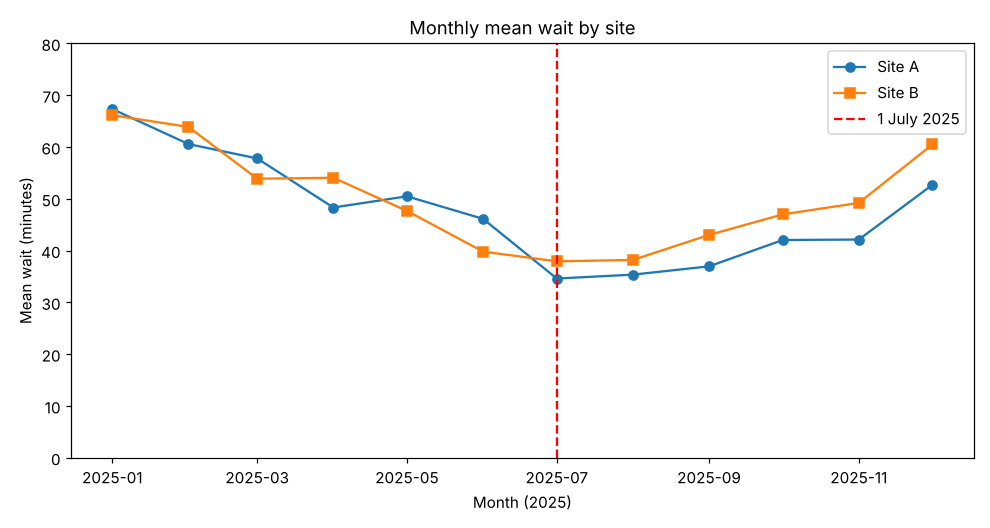

#### Improved prompt output

```
Valid rows used: 4169

(1) Distribution of wait_minutes, all valid rows
Mean: 48.9   Median: 39.0   90th percentile: 98.0   95th percentile: 123.0   Max: 351   Skewness: 1.93

(2) By site and period: mean, median, 90th percentile, n, share waiting over 90 minutes
              mean  median    p90     n  over90
site   post                                    
Site A False  55.0    45.0  109.0  1169    15.4
       True   40.9    32.0   82.0  1175     7.9
Site B False  54.1    43.5  111.1   920    16.2
       True   46.3    37.0   88.0   905     9.2

Monthly mean wait
site        Site A  Site B
month                     
2025-01-01    67.3    66.1
2025-02-01    60.6    63.9
2025-03-01    57.8    53.9
2025-04-01    48.3    54.1
2025-05-01    50.5    47.6
2025-06-01    46.1    39.8
2025-07-01    34.6    37.9
2025-08-01    35.4    38.2
2025-09-01    37.0    43.0
2025-10-01    42.0    47.0
2025-11-01    42.1    49.2
2025-12-01    52.7    60.5
Monthly 90th percentile wait
site        Site A  Site B
month                     
2025-01-01   128.4   126.6
2025-02-01   114.0   135.4
2025-03-01   114.8   112.5
2025-04-01    91.0   102.0
2025-05-01    98.0    97.8
2025-06-01    92.5    77.5
2025-07-01    74.0    74.3
2025-08-01    75.7    68.7
2025-09-01    71.4    79.0
2025-10-01    79.9    98.5
2025-11-01    80.0    92.0
2025-12-01   102.3   107.0

Headline (association language):
Half of patients waited 39 minutes or less, but one in ten waited 98 minutes or more, and the typical and worst waits both fell at both sites into July before rising again.
From July, Site A's waits were lower than Site B's, an association that may reflect the new triage system but is not proof of it.
```

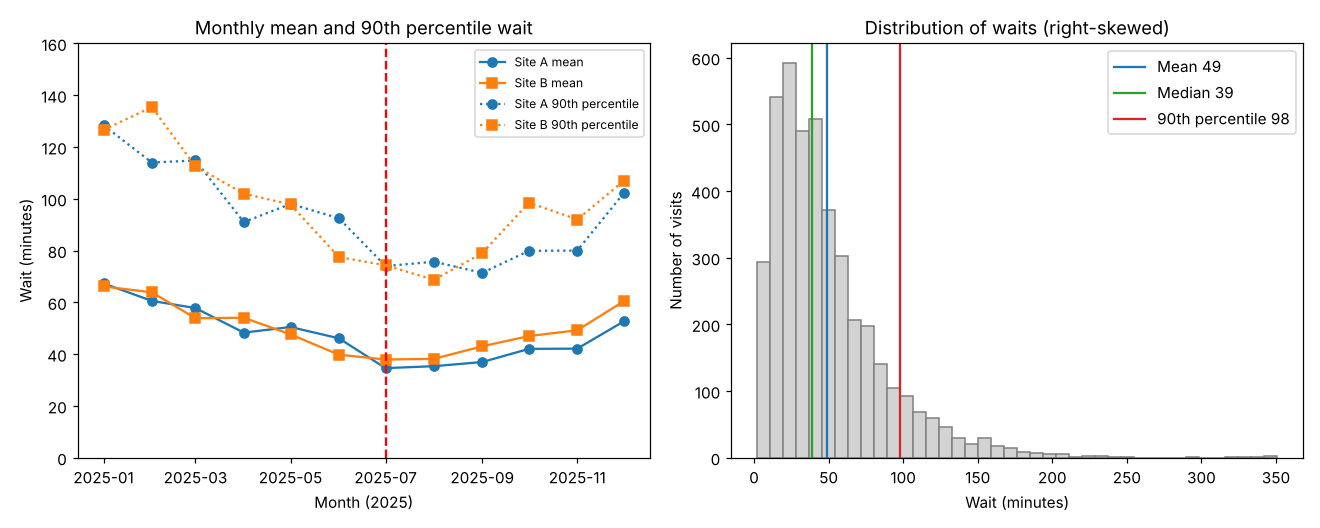

## Task 6: Do older patients wait longer?

Part 1: the correlation and the age group table that the prompt asks for.

Correlation age vs wait_minutes: 0.005
           mean  median     n
age_group                    
0-17       48.8    38.0   573
18-39      47.9    39.0  1340
40-64      49.4    39.0  1623
65+        50.0    40.0   633


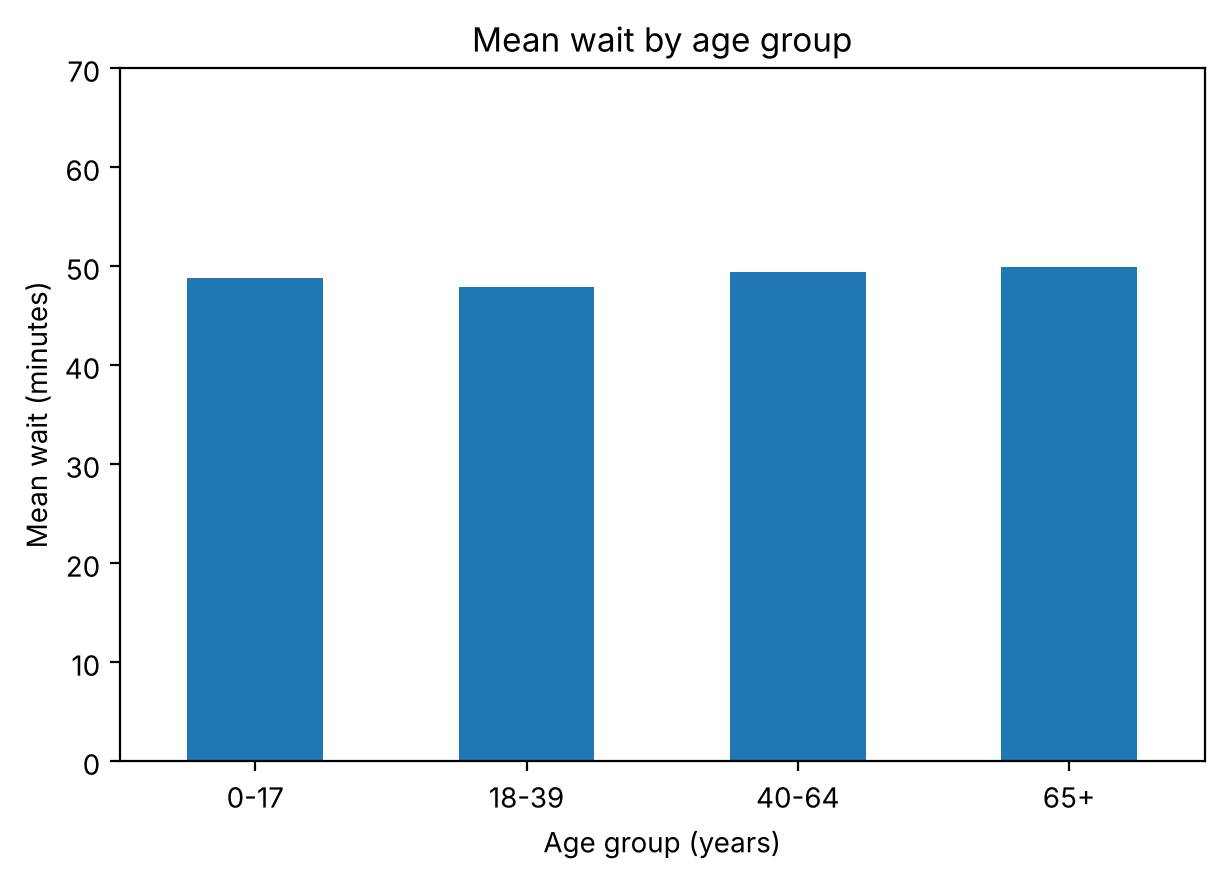

In [26]:
print('Correlation age vs wait_minutes:', round(clean.age.corr(clean.wait_minutes), 3))
clean['age_group'] = pd.cut(clean.age, [-1, 17, 39, 64, 200], labels=['0-17', '18-39', '40-64', '65+'])
by_age = clean.groupby('age_group', observed=True).wait_minutes.agg(mean='mean', median='median', n='count')
print(by_age.round(1))

ax = by_age['mean'].plot(kind='bar', figsize=(7, 4.5), color='tab:blue')
ax.set_ylim(0, 70)
ax.set_xlabel('Age group (years)')
ax.set_ylabel('Mean wait (minutes)')
ax.set_title('Mean wait by age group')
plt.xticks(rotation=0)
plt.show()

Part 2: what does drive waiting? Mean and median wait by triage level.

In [27]:
print(clean.groupby('triage_level').wait_minutes.agg(mean='mean', median='median', n='count').round(1))

              mean  median     n
triage_level                    
1              8.9     8.0   169
2             22.3    19.0   639
3             45.4    38.0  1654
4             63.3    54.0  1172
5             72.7    62.0   535


Part 3: could age be hiding behind triage? We check whether age differs by triage level, and whether age matters within each triage level.

In [28]:
print('Mean age by triage level')
print(clean.groupby('triage_level').age.mean().round(1))
print()
print('Mean wait by age group within each triage level')
print(clean.pivot_table(index='triage_level', columns='age_group', values='wait_minutes', aggfunc='mean', observed=True).round(1))

Mean age by triage level
triage_level
1    42.4
2    41.7
3    41.6
4    41.9
5    43.2
Name: age, dtype: float64

Mean wait by age group within each triage level
age_group     0-17  18-39  40-64   65+
triage_level                          
1              8.6    9.1    8.9   9.0
2             24.3   23.0   21.6  20.6
3             46.0   45.5   45.7  43.8
4             62.7   61.4   63.8  66.5
5             69.2   72.1   73.3  75.1


### Answers

Q1. Do you notice any meaningful finding?

Not for age. The mean wait is almost the same in every age group (about 48 to 50 minutes), and the bars in the chart are almost the same height. The meaningful finding is the absence of a relationship.

Q2. What does a correlation of 0.005 tell you? Does the median wait differ much between age groups?

A correlation of 0.005 is essentially zero, so age and wait show no linear relationship. The medians confirm it: 38, 39, 39 and 40 minutes for the four age groups, a difference of only 2 minutes.

Q3. If age does not drive waiting, what does? Mean wait for each triage level.

Triage level does. The mean wait is 8.9 minutes at level 1, 22.3 at level 2, 45.4 at level 3, 63.3 at level 4 and 72.7 at level 5. The more urgent the patient, the shorter the wait.

Q4. Does age differ by triage level? Could age be hiding behind triage?

No. The mean age is about 42 at every triage level (41.6 to 43.2), so older patients are not concentrated in the urgent or non urgent groups. If they were, the effect of age could cancel itself out in the overall figure. Within each triage level the age groups also have similar waits, with a small exception: at levels 4 and 5 the oldest group waits a few minutes longer (about 6 minutes more at level 5 than the youngest group). That is a small pattern and is not enough to change the overall result.

Q5. The nurse manager expected a relationship. What is the honest conclusion?

In this data there is no meaningful association between age and waiting time. What predicts waiting is triage level, which is about urgency. The belief that elderly patients wait longer is not supported here, though a small extra wait for older patients at the least urgent levels could be monitored.

Q6. Improved prompt

The original prompt shows that age does not matter, but not what does, and it does not check whether age is hidden behind triage. The improved prompt adds medians, triage level, age by triage level, and a breakdown inside triage levels.

> Context: the attached CSV has hospital visits with columns visit_id, visit_date, site, department, triage_level (1 = most urgent, 5 = least urgent), age, wait_minutes, treatment_minutes, satisfaction, triage_system. Site A switched to a new triage system on 1 July 2025 and Site B kept the old one. The data has known problems: two date formats (YYYY-MM-DD and DD/MM/YYYY), department labels written as Emergency, emergency, ER and with trailing spaces, exact duplicate rows, negative waits, waits of 999 as a placeholder, and impossible ages (below 0 or above 110). Task: Use valid rows only: parse both date formats, map the Emergency labels to Emergency, drop exact duplicates, drop wait_minutes that are zero, negative or 999, and drop ages below 0 or above 110. (1) Report the Pearson and Spearman correlation between age and wait_minutes. (2) Report mean, median, 90th percentile and n of wait_minutes for age groups 0-17, 18-39, 40-64 and 65+. (3) Report mean and median wait_minutes by triage_level. (4) Report mean age by triage_level, and mean wait by age group within each triage level. (5) Show a bar chart of median wait by age group and a bar chart of mean wait by triage level, both with the y axis starting at 0 and axes labelled with units. Constraints: use association language, say plainly if there is no meaningful relationship, and say whether age could be hiding behind triage level.

### AI result

#### Original prompt output

```
Valid rows used: 4169

Correlation between age and wait_minutes: 0.005
            mean  count
age_group              
0-17       48.80    573
18-39      47.91   1340
40-64      49.38   1623
65+        49.97    633
```

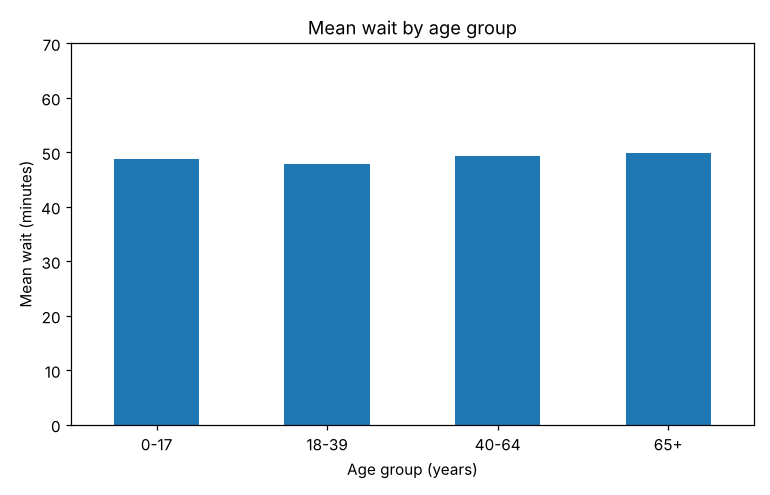

#### Improved prompt output

```
Valid rows used: 4169

(1) Correlation between age and wait_minutes: Pearson 0.005, Spearman 0.006

(2) Wait by age group
           mean  median    p90     n
age_group                           
0-17       48.8    38.0   95.8   573
18-39      47.9    39.0   96.0  1340
40-64      49.4    39.0  100.0  1623
65+        50.0    40.0  100.0   633

(3) Wait by triage level
              mean  median     n
triage_level                    
1              8.9     8.0   169
2             22.3    19.0   639
3             45.4    38.0  1654
4             63.3    54.0  1172
5             72.7    62.0   535

(4) Mean age by triage level (does age differ by urgency?)
              mean  median
triage_level              
1             42.4    41.0
2             41.7    42.0
3             41.6    41.0
4             41.9    42.0
5             43.2    44.0

(5) Mean wait by age group within each triage level
age_group     0-17  18-39  40-64   65+
triage_level                          
1              8.6    9.1    8.9   9.0
2             24.3   23.0   21.6  20.6
3             46.0   45.5   45.7  43.8
4             62.7   61.4   63.8  66.5
5             69.2   72.1   73.3  75.1

Conclusion: age shows essentially no association with waiting time (correlation near 0, similar medians in every age group).
Within triage levels 4 and 5, older patients wait a few minutes longer (about 6 minutes more at level 5 between ages 0-17 and 65+), a small pattern that does not change the overall picture.
Triage level shows a strong association, and mean age is about the same at every triage level, so age is not hiding behind triage.
```

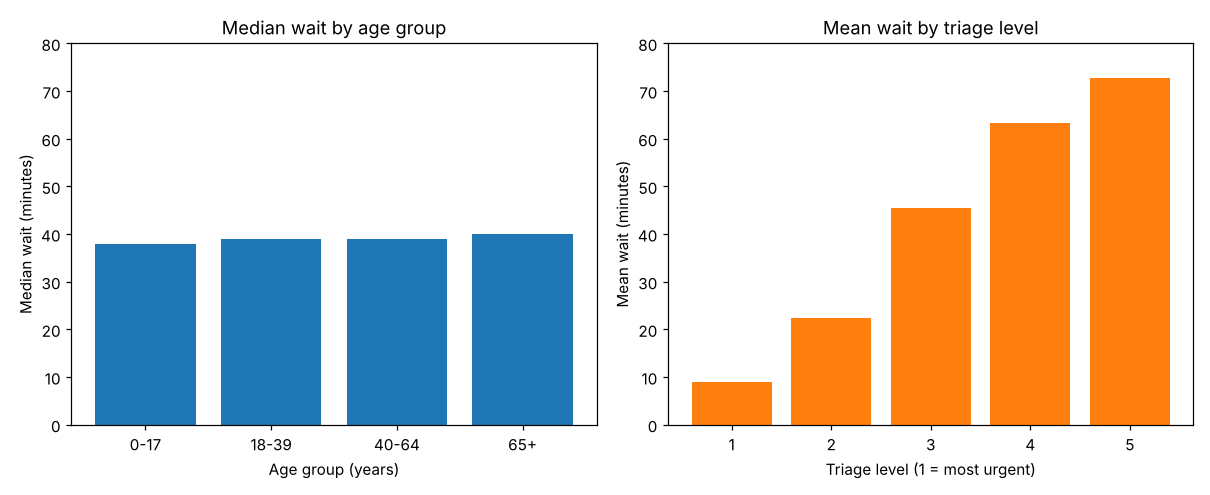

## Task 7: Should we remove the outliers?

Part 1: the IQR rule that the prompt asks for.

In [29]:
w = clean.wait_minutes
q1, q3 = w.quantile(0.25), w.quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
is_out = (w < lower) | (w > upper)

print('Q1:', q1, 'Q3:', q3, 'IQR:', iqr)
print('Fences:', lower, 'and', upper)
print('Outliers:', is_out.sum())
print('Mean with outliers:', round(w.mean(), 2))
print('Mean without outliers:', round(w[~is_out].mean(), 2))

Q1: 22.0 Q3: 64.0 IQR: 42.0
Fences: -41.0 and 127.0
Outliers: 183
Mean with outliers: 48.92
Mean without outliers: 43.65


Part 2: where the flagged visits come from.

In [30]:
flagged = clean[is_out]
print(flagged.department.value_counts())
print()
print(flagged.triage_level.value_counts().sort_index())
print()
print('Outlier rate by triage level (%)')
print((clean.groupby('triage_level').wait_minutes.apply(lambda s: (s > upper).mean() * 100)).round(1))

department
Emergency      127
Orthopedics     35
Cardiology      15
Pediatrics       6
Name: count, dtype: int64

triage_level
3    35
4    89
5    59
Name: count, dtype: int64

Outlier rate by triage level (%)
triage_level
1     0.0
2     0.0
3     2.1
4     7.6
5    11.0
Name: wait_minutes, dtype: float64


Part 3: the shape of the distribution, the longest wait, and the IQR rule applied on a log scale.

Skewness: 1.93 | mean 48.9 vs median 39.0
Longest wait: 351.0
Visits over 180 minutes: 38
Flagged by the IQR rule on log(wait): 43


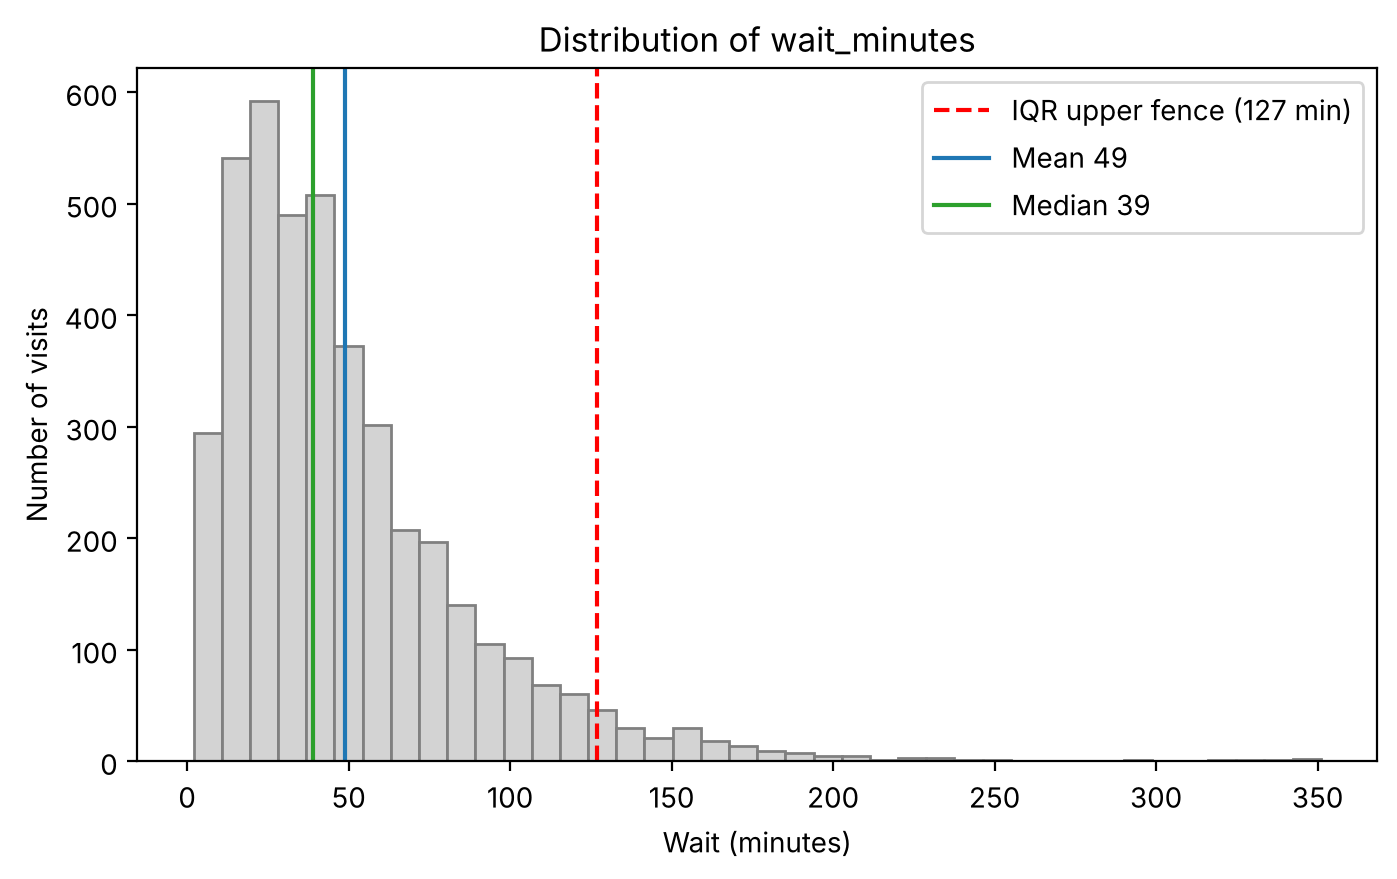

In [31]:
print('Skewness:', round(w.skew(), 2), '| mean', round(w.mean(), 1), 'vs median', w.median())
print('Longest wait:', w.max())
print('Visits over 180 minutes:', (w > 180).sum())

import numpy as np
lw = np.log(w)
lq1, lq3 = lw.quantile(0.25), lw.quantile(0.75)
log_out = (lw > lq3 + 1.5 * (lq3 - lq1)) | (lw < lq1 - 1.5 * (lq3 - lq1))
print('Flagged by the IQR rule on log(wait):', log_out.sum())

plt.figure(figsize=(8, 4.5))
plt.hist(w, bins=40, color='lightgray', edgecolor='gray')
plt.axvline(upper, color='red', linestyle='--', label='IQR upper fence (' + str(round(upper)) + ' min)')
plt.axvline(w.mean(), color='tab:blue', label='Mean ' + str(round(w.mean())))
plt.axvline(w.median(), color='tab:green', label='Median ' + str(round(w.median())))
plt.xlabel('Wait (minutes)')
plt.ylabel('Number of visits')
plt.title('Distribution of wait_minutes')
plt.legend()
plt.show()

Part 4: does removing the outliers change the Site A vs Site B conclusion from Task 2?

In [32]:
def did(x):
    m = x.groupby(['site', 'post']).wait_minutes.mean().unstack()
    change = m[True] - m[False]
    return round(change['Site A'], 2), round(change['Site B'], 2), round(change['Site A'] - change['Site B'], 2)

print('All valid rows   (Site A change, Site B change, DiD):', did(clean))
print('Outliers removed (Site A change, Site B change, DiD):', did(clean[~is_out]))

All valid rows   (Site A change, Site B change, DiD): (np.float64(-14.12), np.float64(-7.82), np.float64(-6.3))
Outliers removed (Site A change, Site B change, DiD): (np.float64(-10.43), np.float64(-4.69), np.float64(-5.74))


### Answers

Q1. Which departments and triage levels do the 183 flagged visits come from? What do you notice?

Emergency accounts for 127 of the 183 (69 percent), then Orthopedics with 35, Cardiology with 15 and Pediatrics with 6. Radiology has none. By triage level, 89 are level 4, 59 are level 5 and 35 are level 3, and none are level 1 or 2. So the long waits are concentrated in the busiest department and among the less urgent patients, which is exactly where we would expect long waits if urgent patients are seen first. The outlier rate rises from 0 percent at levels 1 and 2 to 11 percent at level 5.

Q2. Are these visits data errors, or real long waits? What would a real error look like?

They look like real long waits. A real error would be a value that is impossible or a placeholder, such as a negative wait, a 999, or a wait longer than the whole day. We already removed those in the cleaning step. The remaining flagged waits are plausible (up to a few hours), and they follow a sensible pattern by department and urgency, which errors would not.

Q3. Is the distribution of wait_minutes symmetric? Why does that matter for the IQR rule?

No. It is right skewed: the skewness is 1.9 and the mean (48.9) is well above the median (39). The IQR rule assumes a roughly symmetric distribution. In a skewed distribution the rule flags the natural long tail as outliers. When the same rule is applied on a log scale, which makes the distribution more symmetric, only 43 visits are flagged instead of 183.

Q4. What is the longest wait? How many visits waited over 180 minutes?

The longest wait is 351 minutes (just under 6 hours), and 38 visits waited more than 180 minutes.

Q5. Does removing the outliers change the Site A vs Site B conclusion from Task 2?

Not in a way that matters. With all valid rows, Site A fell by 14.12 minutes, Site B by 7.82, and the difference in differences is minus 6.30. With the outliers removed the changes are minus 10.43 and minus 4.69, and the difference in differences is minus 5.74. The size of each drop changes because the long waits are removed, but Site A still improves by about 6 minutes more than Site B.

The manager's request should be declined. Removing the flagged visits would lower the mean from 48.9 to 43.7 minutes, but only by hiding patients who really waited a long time. It is better to report the median and the 90th percentile alongside the mean.

Q6. Improved prompt

The original prompt only counts the outliers and removes them. The improved prompt asks where they come from, whether the distribution is skewed, whether they look like errors, and whether removing them changes the conclusion.

> Context: the attached CSV has hospital visits with columns visit_id, visit_date, site, department, triage_level (1 = most urgent, 5 = least urgent), age, wait_minutes, treatment_minutes, satisfaction, triage_system. Site A switched to a new triage system on 1 July 2025 and Site B kept the old one. The data has known problems: two date formats (YYYY-MM-DD and DD/MM/YYYY), department labels written as Emergency, emergency, ER and with trailing spaces, exact duplicate rows, negative waits, waits of 999 as a placeholder, and impossible ages (below 0 or above 110). Task: Use valid rows only: parse both date formats, map the Emergency labels to Emergency, drop exact duplicates, drop wait_minutes that are zero, negative or 999, and drop ages below 0 or above 110. Identify outliers in wait_minutes using the IQR method and report how many there are. Do not remove anything yet. (1) Show which departments and triage levels the flagged visits come from, and the outlier rate by triage level. (2) Report skewness, mean and median, and how many visits the IQR rule flags on log(wait_minutes). (3) Report the longest wait and the number of visits over 180 minutes. (4) Report mean and median with and without the flagged visits. (5) Compute the Site A change minus Site B change in mean wait before and after 1 July 2025, with and without the flagged visits. (6) Show a histogram with the IQR fence, mean and median marked. Constraints: say whether the flagged visits look like data errors or real long waits and why, and say whether removing them is justified.

### AI result

#### Original prompt output

```
Valid rows used: 4169

Q1 = 22, Q3 = 64, IQR = 42
Outlier limits: below -41 or above 127 minutes
Number of outliers: 183
Mean wait with outliers: 48.92 minutes
Mean wait without outliers: 43.65 minutes
```

#### Improved prompt output

```
Valid rows used: 4169

(1) IQR rule: upper fence 127 minutes, 183 outliers (4.4% of visits), none below the lower fence
Mean with outliers 48.92, without 43.65; median with 39.0, without 38.0

(2) Where the outliers come from
department
Emergency      127
Orthopedics     35
Cardiology      15
Pediatrics       6
triage_level
3    35
4    89
5    59
Outlier rate by triage level (%):
triage_level
1     0.0
2     0.0
3     2.1
4     7.6
5    11.0

(3) Shape: skewness 1.93, mean 48.9 vs median 39.0 (right-skewed)
IQR rule on log(wait): 43 flagged (the rule flags the long tail of a skewed distribution)

(4) Longest wait: 351 minutes; visits over 180 minutes: 38

All valid rows    Site A change -14.12, Site B change -7.82, DiD -6.30
Outliers removed  Site A change -10.43, Site B change -4.69, DiD -5.74

Conclusion: the flagged visits are long but plausible waits for low-urgency patients, mainly in Emergency.
Removing them would hide real long waits, so they should be kept and reported with the median and 90th percentile.
```

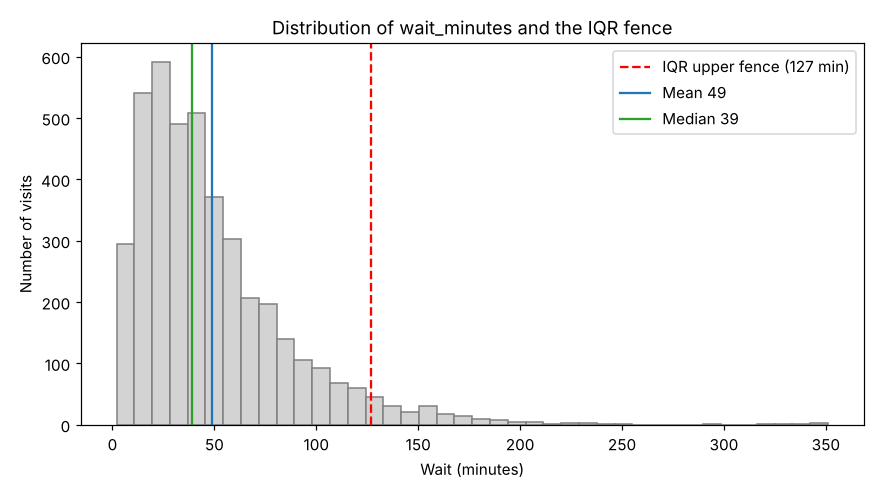

## Task 8: Is the improvement statistically real?

Part 1: the test the prompt asks for (Site A, one-sided Welch t-test), and the same test on Site B, which never got the new system.

In [33]:
from scipy import stats

for site in ['Site A', 'Site B']:
    x = clean[clean.site == site]
    before = x[~x.post].wait_minutes
    after = x[x.post].wait_minutes
    t = stats.ttest_ind(after, before, equal_var=False, alternative='less')
    diff = after.mean() - before.mean()
    se = (after.var() / len(after) + before.var() / len(before)) ** 0.5
    print(site, '| change:', round(diff, 2), '| p-value:', t.pvalue, '| 95% CI:', round(diff - 1.96 * se, 2), 'to', round(diff + 1.96 * se, 2))

Site A | change: -14.12 | p-value: 7.71102639698813e-21 | 95% CI: -17.07 to -11.17
Site B | change: -7.82 | p-value: 7.0463683807179215e-06 | 95% CI: -11.34 to -4.3


Part 2: the comparison that answers the director's question. The difference in differences with a bootstrap 95 percent confidence interval. We resample the visits within each site and period 5000 times and recompute the difference in differences each time.

DiD: -6.3 | bootstrap 95% CI: -10.87 to -1.83


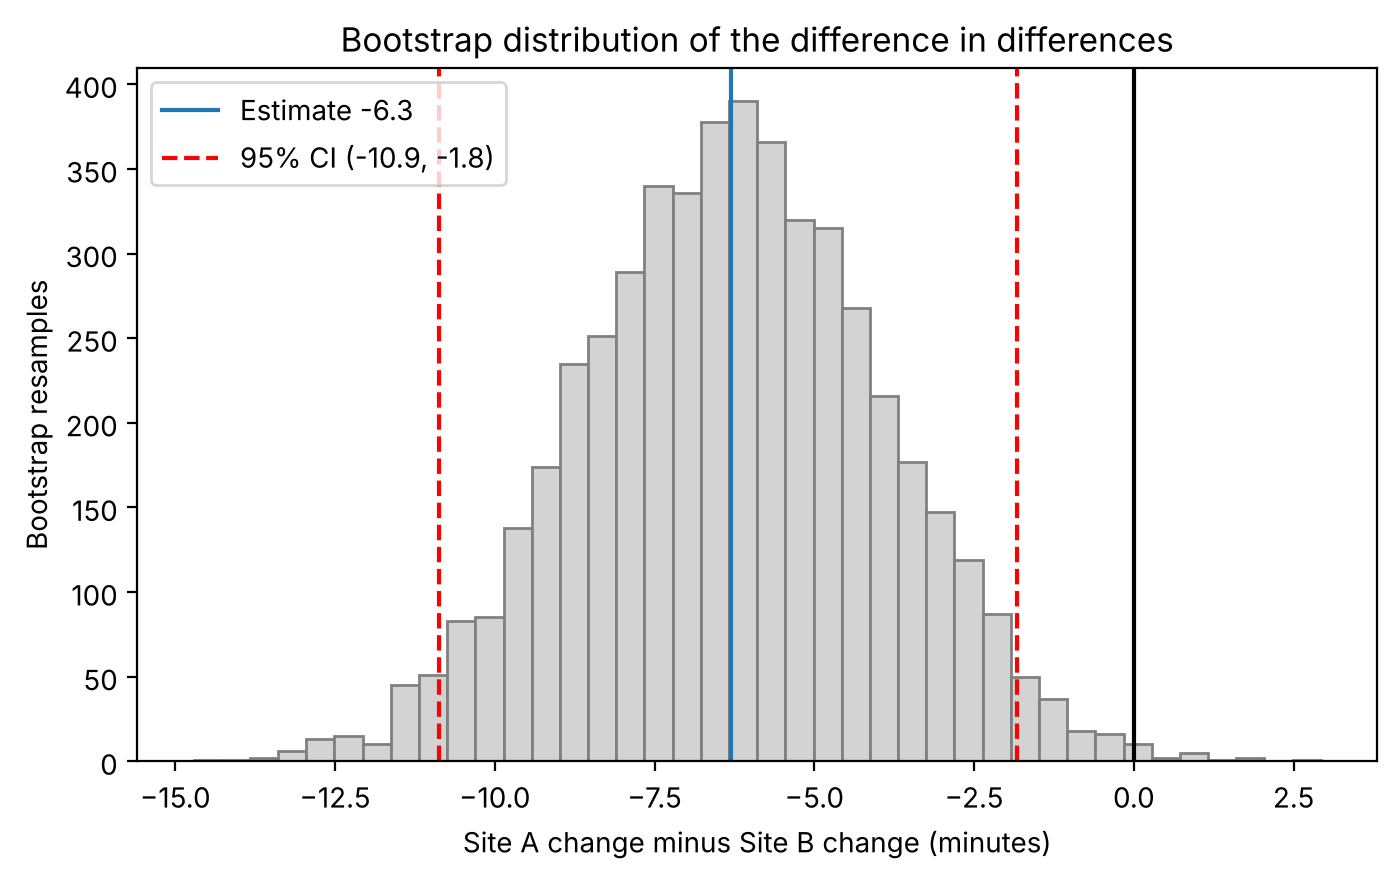

In [34]:
import numpy as np

rng = np.random.default_rng(42)
groups = {}
for s in ['Site A', 'Site B']:
    for p in [False, True]:
        groups[(s, p)] = clean[(clean.site == s) & (clean.post == p)].wait_minutes.values

def did_from(m):
    return (m['Site A', True] - m['Site A', False]) - (m['Site B', True] - m['Site B', False])

observed = did_from({k: v.mean() for k, v in groups.items()})

boot = []
for i in range(5000):
    m = {k: rng.choice(v, len(v)).mean() for k, v in groups.items()}
    boot.append(did_from(m))

low, high = np.percentile(boot, [2.5, 97.5])
print('DiD:', round(observed, 2), '| bootstrap 95% CI:', round(low, 2), 'to', round(high, 2))

plt.figure(figsize=(8, 4.5))
plt.hist(boot, bins=40, color='lightgray', edgecolor='gray')
plt.axvline(observed, color='tab:blue', label='Estimate ' + str(round(observed, 1)))
plt.axvline(low, color='red', linestyle='--', label='95% CI (' + str(round(low, 1)) + ', ' + str(round(high, 1)) + ')')
plt.axvline(high, color='red', linestyle='--')
plt.axvline(0, color='black')
plt.xlabel('Site A change minus Site B change (minutes)')
plt.ylabel('Bootstrap resamples')
plt.title('Bootstrap distribution of the difference in differences')
plt.legend()
plt.show()

Part 3: the share of urgent patients (triage levels 1 and 2) at each site, before and after.

In [35]:
clean['urgent'] = clean.triage_level <= 2
urgent = (clean.groupby(['site', 'post']).urgent.mean() * 100).round(1).unstack()
urgent.columns = ['before (%)', 'after (%)']
urgent['change (points)'] = urgent['after (%)'] - urgent['before (%)']
print(urgent)

        before (%)  after (%)  change (points)
site                                          
Site A        18.7       21.7              3.0
Site B        20.8       15.8             -5.0


Part 4: the difference in differences adjusted for department and triage level. We fit a regression where the interaction term is the difference in differences, and we add department and triage level as controls.

In [36]:
import statsmodels.formula.api as smf

clean['post_int'] = clean.post.astype(int)
clean['is_A'] = (clean.site == 'Site A').astype(int)

plain = smf.ols('wait_minutes ~ is_A * post_int', clean).fit()
adjusted = smf.ols('wait_minutes ~ is_A * post_int + C(department) + C(triage_level)', clean).fit()

for name, model in [('Unadjusted', plain), ('Adjusted', adjusted)]:
    ci = model.conf_int().loc['is_A:post_int']
    print(name, '| DiD:', round(model.params['is_A:post_int'], 2), '| 95% CI:', round(ci[0], 2), 'to', round(ci[1], 2), '| p-value:', round(model.pvalues['is_A:post_int'], 4))

Unadjusted | DiD: -6.3 | 95% CI: -10.86 to -1.74 | p-value: 0.0068
Adjusted | DiD: -4.07 | 95% CI: -7.58 to -0.57 | p-value: 0.0228


This part needs the statsmodels package. If it is not installed, run pip install statsmodels once in a terminal.

### Answers

Q1. Run the same test on Site B. What p-value do you get? What does that say about the AI's test?

Site B's mean wait also fell, by 7.8 minutes, with a p-value of about 0.000007. Site B never got the new system, yet its drop is also highly significant. So a significant p-value for Site A does not tell us the new system worked. The test only says that waits were lower after July than before, and Site B shows that waits fell anyway.

Q2. A tiny p-value comes from a large sample. Does significant mean large or caused by the system?

Neither. Significant means that a difference this big is unlikely to appear by chance alone if there were no real change in the waits between the two periods. With more than 1,100 visits in each period, even a small difference becomes significant. It says nothing about how large the effect is or what produced it. A cause needs a design that rules out other explanations, such as a comparison site.

Q3. Which comparison answers the director's question? Compute it with a bootstrap 95 percent CI.

The difference in differences, Site A change minus Site B change. It is minus 6.30 minutes with a bootstrap 95 percent confidence interval of about minus 10.9 to minus 1.8 minutes. The interval does not include zero, so Site A's improvement is larger than Site B's, but the estimate is imprecise: the true value could plausibly be anywhere from about 2 to 11 minutes.

Q4. Compare the share of urgent patients at each site. How could this distort the comparison?

At Site A the share of urgent patients (levels 1 and 2) rose from 18.7 to 21.7 percent, while at Site B it fell from 20.8 to 15.8 percent. Urgent patients wait far less than others, so a rising urgent share pulls Site A's mean wait down and a falling urgent share pushes Site B's mean up. Both effects make Site A look better compared with Site B even if the triage system did nothing. So the raw difference in differences probably overstates the benefit.

Q5. Adjust the comparison for department and triage level. How does the estimate change?

The estimate shrinks from minus 6.30 to minus 4.07 minutes, with a 95 percent confidence interval of minus 7.6 to minus 0.6. It is still below zero, but it is about a third smaller, and the interval comes close to zero.

Q6. A sentence the director could safely say to the board.

After allowing for the drop that also happened at Site B and for differences in department and urgency mix, waits at Site A fell by about 4 minutes more than at Site B, which is consistent with a modest benefit of the new triage system, although this comparison cannot prove that the system was the cause.

Q7. Improved prompt

The original prompt tests Site A on its own, so it cannot separate the new system from the seasonal fall in waits. The improved prompt adds the Site B test, the difference in differences with a bootstrap interval, the urgent share, and an adjusted estimate.

> Context: the attached CSV has hospital visits with columns visit_id, visit_date, site, department, triage_level (1 = most urgent, 5 = least urgent), age, wait_minutes, treatment_minutes, satisfaction, triage_system. Site A switched to a new triage system on 1 July 2025 and Site B kept the old one. The data has known problems: two date formats (YYYY-MM-DD and DD/MM/YYYY), department labels written as Emergency, emergency, ER and with trailing spaces, exact duplicate rows, negative waits, waits of 999 as a placeholder, and impossible ages (below 0 or above 110). Task: Use valid rows only: parse both date formats, map the Emergency labels to Emergency, drop exact duplicates, drop wait_minutes that are zero, negative or 999, and drop ages below 0 or above 110. (1) Run a one-sided Welch t-test that mean wait_minutes after 1 July 2025 is lower than before, for Site A and also for Site B, and report the change and p-value for each. (2) Compute the difference in differences (Site A change minus Site B change) with a bootstrap 95% confidence interval (5000 resamples within each site and period, fixed random seed). (3) Report the share of urgent patients (triage_level 1 or 2) by site and period. (4) Estimate the difference in differences with OLS, unadjusted and adjusted for department and triage_level, with 95% confidence intervals. (5) Show a histogram of the bootstrap estimates with the confidence interval marked. Constraints: explain the difference between statistically significant and caused by the system, use association language, and finish with one sentence that could be safely said to a hospital board. Show the code.

### AI result

#### Original prompt output

```
Valid rows used: 4169

Site A mean before: 54.98 (n = 1169), after: 40.86 (n = 1175)
Difference (after - before): -14.12 minutes
Welch t-test (one-sided, after < before): t = -9.38, p = 7.71e-21
95% confidence interval for the difference: (-17.07, -11.17)

Conclusion: Site A's mean wait after 1 July is significantly lower than before (p < 0.001).
```

#### Improved prompt output

```
Valid rows used: 4169

(1) Before vs after at each site (Welch t-test, one-sided: after < before)
Site A: change -14.12 minutes, p = 7.71e-21
Site B: change -7.82 minutes, p = 7.05e-06

(2) Difference in differences with a bootstrap 95% CI (5000 resamples within each site and period)
DiD = -6.30 minutes, bootstrap 95% CI (-10.87, -1.83)

(3) Share of urgent patients (triage level 1-2), %
post    Before  After
site                 
Site A    18.7   21.7
Site B    20.8   15.8

(4) Difference in differences adjusted for department and triage level (OLS)
Unadjusted DiD = -6.30, 95% CI (-10.86, -1.74), p = 0.0068
Adjusted   DiD = -4.07, 95% CI (-7.58, -0.57), p = 0.0228

Suggested sentence: After allowing for the change at Site B and for differences in department and urgency mix, waits at Site A fell by about 4 minutes more than at Site B, an association consistent with a modest benefit of the new system but not proof that it caused the change.
```

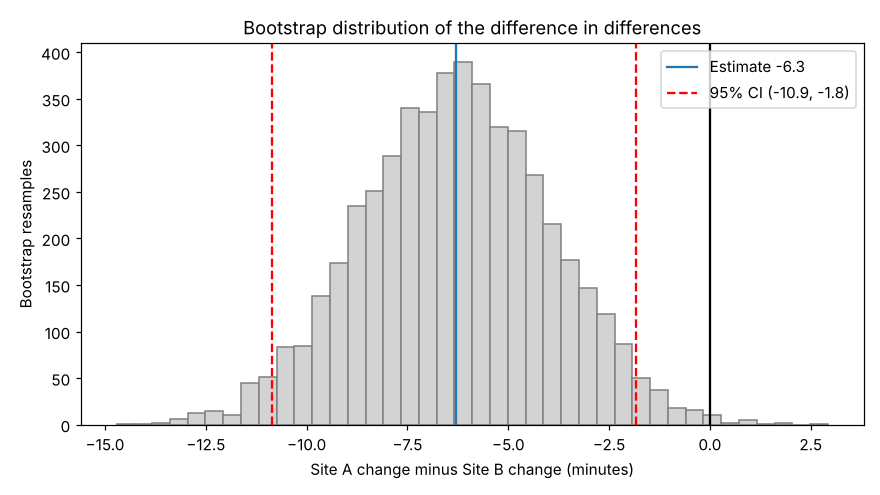